# Numerai Classic v6.0 ("Unity") — MiniRocket Regressor (`NumeraiExtractions` + `MiniRocketNumeraiEstimator`)

- **Data Loading (`data_utils.load_unity_numerai_data_cached`)**: Resolves and downloads the Unity v6.0 Parquets using the official Kaggle clients (`kagglehub.dataset_download` and `kaggle.api.kaggle_api_extended.KaggleApi`) with `numerapi.NumerAPI` fallback, caches processed Parquets, and supports independent training & validation downsampling (`downsample_mode`/`downsample_frac` and `val_downsample_mode`/`val_downsample_frac`).
- **Exploratory Data Analysis (`# EDA`)**: Lists available `TARGET_COL` and `feature_set` options from `features.json`, inspects `train_df.head(2)` / `validation_df.head(2)` and `info()`, plots era sizes over time, overlays feature standard-deviation distributions across Train vs. Validation, and displays the top 10 features correlated with `TARGET_COL` along with ADF stationarity checks.

---

### 1. Feature Extraction Parameters (`utils.NumeraiExtractions` — `estimator__extractor__*`)
- Shared across `baseline_unity.ipynb`, `lightgbm_unity.ipynb`, and `minirocket_unity.ipynb` (correlation ranking, variance filtering, sparse selection, PCA, cross-sectional quantization, rolling-era & lag-diff statistics, per-ticker time-series features, and Fourier harmonics).

---

### 2. Shared Parent Estimator Parameters (`baseline_utils.BaseNumeraiEstimator` — `estimator__*`)
- **`correlation_method`** (`[None, 'pandas_mean', 'numerai_mean', 'pearson', 'spearman']`): How the estimator scores post-extraction features against `TARGET_COL` (used when `top_k` is set).
- **`abs_corr`** (`[True, False]`): `True` selects top features by $|\text{corr}|$; `False` selects by signed $\text{corr}$.
- **`top_k`** (`[None, 20, 40, 80]`): Number of top post-extraction features passed to MiniRocket (`None` uses all extracted features).
- **`era_weighting`** (`[None, 'equal_era', 'recency_linear', 'recency_exp']`): Computes per-row `sample_weight` passed into the linear head (`None`, equal weight per era, linear recency, or exponential recency decay).
- **`recency_decay`** (`Real(0.001, 0.020)`): Exponential decay rate per era when `era_weighting='recency_exp'`.
- **`prediction_transform`** (`[None, 'era_zscore', 'era_rank']`): Post-prediction within-era normalization (`None` = raw, `'era_zscore'`, or `'era_rank'`).
- **`bias_correction`** (`[None, 'mean_residual']`): When `'mean_residual'`, records `mean(y_train - y_hat_train)` in `fit()` and adds it to predictions in `predict()` (`None` disables).
- **Walk-Forward & Horizon Controls**: `walk_forward_step_eras`, `walk_forward_window`, `target_horizon_eras`, `era_stride`.

---

### 3. MiniRocket Model Parameters (`minirocket_utils.MiniRocketNumeraiEstimator` — `estimator__*`)
- **Sequence Construction**:
  - **`input_mode`** (`['ticker_sequence', 'feature_profile']`): `'ticker_sequence'` constructs a strictly causal multivariate `(C, seq_len)` sequence per `numerai_ticker` with a training tail buffer for leak-free validation warm-up; `'feature_profile'` applies univariate MiniRocket across each row's feature vector.
  - **`seq_len`** (`[9, 12, 16, 24]`): Causal lookback window length in eras (minimum `9` to match MiniRocket's length-9 kernels).
  - **`max_channels`** (`[8, 16, 32]`): Maximum top-ranked feature channels fed into multivariate MiniRocket.
  - **`pad_mode`** (`['first', 'neutral']`): Left-padding strategy for tickers with fewer than `seq_len` historical eras (`'first'` repeats earliest value; `'neutral'` pads with `2.0`).
- **MiniRocket Kernel & Dilation Bank (Dempster et al., 2021)**:
  - **`num_kernels`** (`[420, 840, 1680, 3360]`): Number of PPV features (rounded to a multiple of the 84 fixed length-9 `{-1, +2}` kernels).
  - **`max_dilations_per_kernel`** (`[4, 8, 16, 32]`): Maximum exponentially spaced dilations per base kernel.
  - **`fit_sample_size`** (`[1024, 2048, 4096]`): Training subsample size used to draw quantile biases.
  - **`backend`** (`['numpy', 'sktime', 'auto']`): Pure-NumPy vectorized Dempster-2021 MiniRocket (`'numpy'`, zero JIT cold-start & Kaggle-portable) or `sktime` Numba backend (`'sktime'` / `'auto'`).
- **OOM-Proof Batched Linear Head**:
  - **`standardize_features`** (`[True, False]`): Standardizes PPV features before fitting the linear head.
  - **`head_type`** (`['ridge_cv', 'ridge', 'sgd_elasticnet', 'sgd_huber']`): Single-pass batched analytical Ridge / RidgeCV (GCV) or batched SGD head (`elasticnet` / `huber`) — never materializes `(N, num_kernels)` in RAM.
  - **`alpha`** (`[1.0, 10.0, 100.0, 1000.0]` / `Real(1e-2, 1e5, prior='log-uniform')`): Regularization strength for `'ridge'` / SGD heads.
  - **`l1_ratio`** (`[0.05, 0.15, 0.5]` / `Real(0.0, 1.0)`): ElasticNet mixing parameter (active when `head_type='sgd_elasticnet'`).
  - **`huber_epsilon`** (`[1.1, 1.35, 1.75]` / `Real(1.05, 2.5)`): Huber outlier threshold (active when `head_type='sgd_huber'`).


In [1]:
import gc
import os
import sys
import json
import time
import warnings
import importlib
from pathlib import Path
from datetime import datetime

python_env_dir = Path(sys.executable).parent
library_bin_dir = python_env_dir / 'Library' / 'bin'
if library_bin_dir.is_dir() and str(library_bin_dir) not in os.environ.get('PATH', ''):
    os.environ['PATH'] = str(library_bin_dir) + os.pathsep + str(python_env_dir) + os.pathsep + os.environ.get('PATH', '')

import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
try:
    import seaborn as sns
except ImportError:
    sns = None
from IPython.display import display

warnings.filterwarnings('ignore')

# Local, Kaggle (/kaggle/input, /kaggle/usr/lib, /kaggle/working), & nested dataset path routing
current_dir = os.getcwd()
workspace_root = current_dir
if os.path.basename(current_dir).lower() == 'notebooks':
    workspace_root = os.path.dirname(current_dir)

src_path = os.path.join(workspace_root, 'src')
if workspace_root not in sys.path:
    sys.path.insert(0, workspace_root)
if os.path.isdir(src_path) and src_path not in sys.path:
    sys.path.insert(0, src_path)

module_search_roots = [
    Path(workspace_root),
    Path('/kaggle/working'),
    Path('/kaggle/usr/lib'),
    Path('/kaggle/input'),
]
for search_root in module_search_roots:
    if not search_root.is_dir():
        continue
    for target_file in ('afml_utils.py', 'data_utils.py', 'utils.py', 'baseline_utils.py', 'minirocket_utils.py'):
        for found_path in search_root.rglob(target_file):
            parent_dir = str(found_path.parent)
            if parent_dir not in sys.path:
                sys.path.insert(0, parent_dir)

from pandas.plotting import autocorrelation_plot
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from statsmodels.graphics.gofplots import qqplot

from numerai_tools.scoring import numerai_corr

try:
    import skopt
    from skopt import BayesSearchCV
    from skopt.space import Categorical, Integer, Real
    SKOPT_AVAILABLE = True
except ImportError:
    BayesSearchCV = None
    Categorical = Integer = Real = None
    SKOPT_AVAILABLE = False

try:
    import wandb
except ImportError:
    wandb = None

try:
    import afml_utils
    import data_utils
    import utils
    import baseline_utils
    import minirocket_utils
except ModuleNotFoundError as import_err:
    mounted_kaggle_inputs = [str(p) for p in sorted(Path('/kaggle/input').iterdir())] if Path('/kaggle/input').is_dir() else []
    raise ModuleNotFoundError(
        f"{import_err}. Could not locate data_utils.py / utils.py / baseline_utils.py / minirocket_utils.py in "
        f"workspace_root={workspace_root}, /kaggle/working, /kaggle/usr/lib, or /kaggle/input "
        f"(mounted inputs: {mounted_kaggle_inputs}). "
        "On Kaggle, attach a Dataset or Utility Script containing src/data_utils.py, src/utils.py, src/baseline_utils.py, and src/minirocket_utils.py."
    ) from import_err
importlib.reload(afml_utils)
importlib.reload(data_utils)
importlib.reload(utils)
importlib.reload(baseline_utils)
importlib.reload(minirocket_utils)
from data_utils import (
    compute_per_ticker_timeseries_features,
    discover_and_fetch_v6_meta_or_benchmark,
    load_unity_numerai_data,
    load_unity_numerai_data_cached,
)
from utils import (
    NumeraiExtractions,
    build_experiment_setup,
    build_conditional_bayesian_spaces,
    build_quick_results_df,
    candidate_score,
    compute_eda_era_stationarity,
    compute_era_error_envelope,
    configure_error_binning,
    compute_feature_exposure,
    compute_feature_target_correlations,
    compute_per_era_mmc,
    compute_per_era_numerai_corr,
    compute_per_era_spearman_corr,
    deduplicate_param_grid,
    drop_constant_dims,
    evaluate_numerai_predictions,
    export_diagnostics_predictions,
    plot_era_error_envelope,
    plot_residual_diagnostics,
    plot_stake_pnl_dashboard,
    plot_stake_pnl_monte_carlo,
    prepare_bayesian_space,
    prepare_tuned_pipeline,
    quantize_to_5bins,
    reset_cv_metric_log,
    sharpe_ratio,
    simulate_stake_pnl,
    simulate_stake_pnl_monte_carlo,
    build_live_staking_scenarios_df,
    compute_deflated_sharpe_ratio,
    compute_probabilistic_sharpe_ratio,
    run_numereval_diagnostics,
    simulate_live_staking_scenarios,
    walk_forward_predict,
    CombinatorialPurgedEraCV,
    PurgedEraKFold,
    build_era_cv_splits,
    compute_clustered_mda,
    compute_drawdown_and_tuw,
    compute_hhi_concentration,
    compute_lo_adjusted_sharpe,
    compute_min_track_record_length,
    compute_pbo_cscv,
    compute_per_era_fnc,
    compute_r1399_churn_retention,
    compute_strategy_risk,
    compute_versioned_candidate_score,
    make_candidate_scorer,
    neutralize_predictions,
    purge_train_before_validation,
    summarize_afml_backtest_diagnostics,
)
from baseline_utils import BaseNumeraiEstimator, configure_extraction_cache
from minirocket_utils import MiniRocketNumeraiEstimator, SKTIME_MINIROCKET_AVAILABLE

print('Imports loaded successfully')
print(f'workspace_root={workspace_root} | SKOPT_AVAILABLE={SKOPT_AVAILABLE} | SKTIME_MINIROCKET_AVAILABLE={SKTIME_MINIROCKET_AVAILABLE}')

Imports loaded successfully
workspace_root=/kaggle/working | SKOPT_AVAILABLE=True | SKTIME_MINIROCKET_AVAILABLE=False


# Setup

In [2]:
# --- Experiment Knobs (only things you actually change) ---
TARGET_COL = 'target'          # Training target (auto-sets horizon & embargo)
feature_set = 'all'          # 'small', 'medium', or 'all'
era_stride = 4                 # 1, 2, 4 (20d), or 12 (60d)

search_mode = 'bayes'          # 'grid' or 'bayes'
score_version = 'v1_skepta'    # 'v0_default', 'v1_skepta', or 'v2_skepta_mmc'
eval_mode = 'both'             # 'static', 'walk_forward', or 'both'
cv_strategy = 'timeseries'   # 'timeseries', 'purged_kfold' (AFML Ch. 7), or 'cpcv' (AFML Ch. 12)
n_splits = 1
cv_split = 0.8                 # Chronological CV train/test split ratio (used when n_splits == 1)
downsample_mode = 'within_era'         # None, 'within_era', 'recent', 'earliest', 'uniform', or 'random_eras'
downsample_frac = 0.01          # Fraction of strided training data to keep in (0.0, 1.0]
val_downsample_mode = 'within_era'     # Validation: None (100%), 'same', 'within_era', 'recent', 'earliest', 'uniform', or 'random_eras'
val_downsample_frac = 0.01             # Fraction of validation data to keep in (0.0, 1.0] (None mirrors downsample_frac)
n_iter = 1
n_jobs = -1                    # Worker thread count (inner CV stays 1 to avoid RAM duplication)
save_results = True
error_bin_mode = 'pct'         # 'pct' (% error + zero-target tol) or 'abs' (raw residual bins)

setup_cfg = build_experiment_setup(
    target_col=TARGET_COL,
    feature_set=feature_set,
    era_stride=era_stride,
    model_tag='minirocket',
    search_mode=search_mode,
    score_version=score_version,
    eval_mode=eval_mode,
    cv_strategy=cv_strategy,
    n_splits=n_splits,
    cv_split=cv_split,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    val_downsample_mode=val_downsample_mode,
    val_downsample_frac=val_downsample_frac,
    n_iter=n_iter,
    n_jobs=1,
    lgbm_n_jobs=n_jobs,
    save_results=save_results,
    error_bin_mode=error_bin_mode,
    workspace_root=workspace_root,
    wandb_project='numerai-minirocket',
)
globals().update(setup_cfg)


Experiment: numerai_v6.0_all_eras_stride4_minirocket | model=minirocket | search_mode=bayes | cv_strategy=timeseries (cv_split=0.8) | ERA_COL=era | TARGET_COL=target | era_stride=4 | horizon=12 | embargo=3 | downsample(train=within_era@0.01, val=within_era@0.01)
[Overlap Notice] TARGET_COL='target' has horizon=12 eras while era_stride=4 (~3.0x label overlap). Consider era_stride=12 or era_weighting='uniqueness'.


# Prep

In [3]:
_prep_t0 = time.perf_counter()
train_df, validation_df, feature_columns, feature_metadata = load_unity_numerai_data_cached(
    data_version=data_version,
    data_folder=data_folder,
    kaggle_dataset=kaggle_dataset,
    feature_set=feature_set,
    target_col=TARGET_COL,
    era_stride=era_stride,
    downsample_mode=downsample_mode,
    downsample_frac=downsample_frac,
    val_downsample_mode=val_downsample_mode,
    val_downsample_frac=val_downsample_frac,
    random_state=random_state,
    ticker_timeseries_features=ticker_timeseries_features,
    ticker_rolling_windows=ticker_rolling_windows,
    ticker_lag_steps=ticker_lag_steps,
    workspace_root=workspace_root,
    auto_download=True,
    use_numerapi_fallback=True,
    force_reload=force_reload_data_cache,
)
prep_elapsed_s = time.perf_counter() - _prep_t0
print(f'Loaded {len(feature_columns)} int8 features | train={train_df.shape} ({train_df[ERA_COL].nunique()} eras) | validation={validation_df.shape} ({validation_df[ERA_COL].nunique()} eras)')

Loaded 1040 int8 features | train=(10834, 1045) (209 eras) | validation=(26550, 1045) (398 eras)


## Exploratory Data Analysis (EDA)

In [4]:
available_targets = list(feature_metadata.get('targets', [TARGET_COL]))
print(f'Available TARGET_COL options ({len(available_targets)}):', available_targets)
print('Available feature_set options:', {k: len(v) for k, v in feature_metadata.get('feature_sets', {}).items()})

print('\nTraining data:')
display(train_df.head(2))
print('Validation data:')
display(validation_df.head(2))
print('Training set info:')
train_df.info()
print('\nValidation set info:')
validation_df.info()

Available TARGET_COL options (24): ['target', 'target_raw_return_20', 'target_raw_return_60', 'target_factor_neutral_20', 'target_factor_neutral_60', 'target_factor_feat_neutral_20', 'target_factor_feat_neutral_60', 'target_camille_20', 'target_camille_60', 'target_sydney_20', 'target_sydney_60', 'target_irina_20', 'target_irina_60', 'target_alexandra_20', 'target_alexandra_60', 'target_colleen_20', 'target_colleen_60', 'target_jean_20', 'target_jean_60', 'target_eleven_4', 'target_eleven_20', 'target_eleven_60', 'target_jupiter_20', 'target_jupiter_60']
Available feature_set options: {'small': 101, 'medium': 351, 'all': 1040, 'signals': 23}

Training data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_2,feature_intelligence_3,feature_intelligence_4,feature_intelligence_5,feature_intelligence_6,feature_intelligence_7,...,feature_rsi_130d_country_ranknorm,feature_rsi_60d_country_ranknorm,feature_rsi_90d_country_ranknorm,feature_trix_130d_country_ranknorm,feature_trix_60d_country_ranknorm,feature_value_factor,feature_volatility_factor,feature_country,target,era
204,2003-01-03,train,669 HK,3,1,0,0,0,0,4,...,2,2,2,2,2,-1,2,2,0.50,1
212,2003-01-03,train,6762 JP,3,4,4,0,0,0,2,...,2,2,2,2,2,-1,2,2,0.75,1


Validation data:


,date,data_type,numerai_ticker,feature_intelligence_1,feature_intelligence_2,feature_intelligence_3,feature_intelligence_4,feature_intelligence_5,feature_intelligence_6,feature_intelligence_7,...,feature_rsi_130d_country_ranknorm,feature_rsi_60d_country_ranknorm,feature_rsi_90d_country_ranknorm,feature_trix_130d_country_ranknorm,feature_trix_60d_country_ranknorm,feature_value_factor,feature_volatility_factor,feature_country,target,era
270,2019-01-04,validation,112040 KR,2,2,2,3,3,3,4,...,0,2,1,-2,-2,-1,2,2,0.50,836
392,2019-01-04,validation,1802 JP,4,3,4,0,0,0,2,...,0,1,1,0,0,1,-1,2,0.75,836


Training set info:
<class 'pandas.core.frame.DataFrame'>
Index: 10834 entries, 204 to 1082590
Columns: 1045 entries, date to era
dtypes: datetime64[ms](1), float32(1), int32(1), int8(1040), object(2)
memory usage: 11.2+ MB

Validation set info:
<class 'pandas.core.frame.DataFrame'>
Index: 26550 entries, 270 to 2653641
Columns: 1045 entries, date to era
dtypes: datetime64[ms](1), float32(1), int32(1), int8(1040), object(2)
memory usage: 27.3+ MB


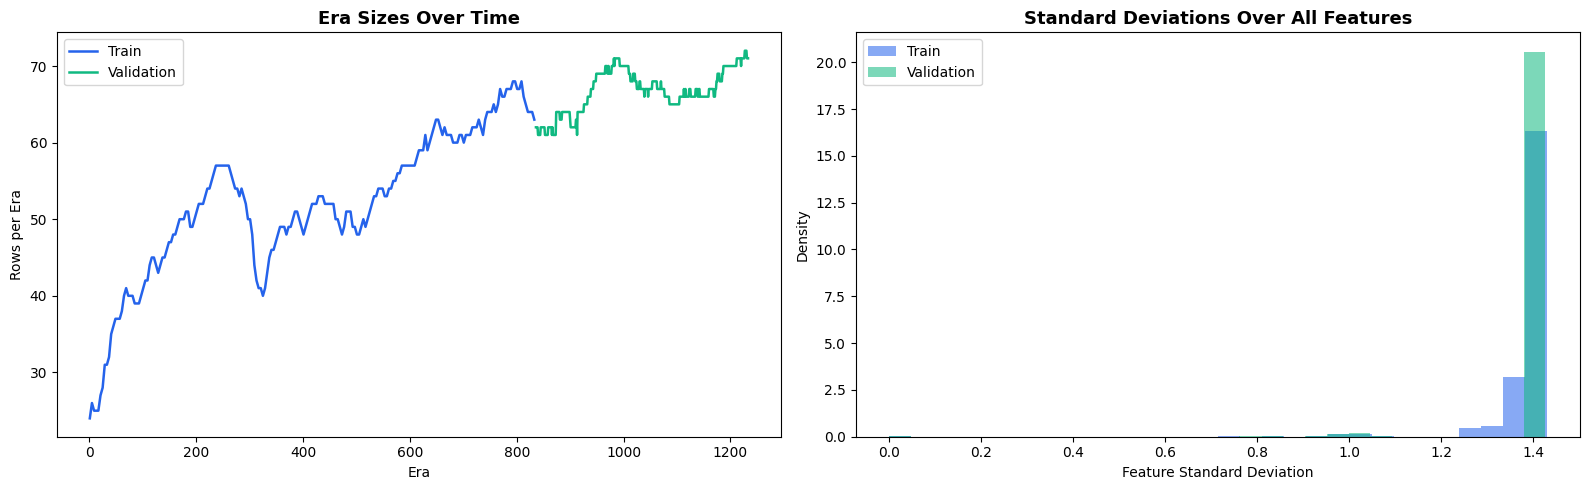

Top 10 Features according to absolute correlation with target:


feature_charisma_54         0.034248
feature_strength_75         0.033643
feature_constitution_172    0.033100
feature_charisma_53         0.030747
feature_constitution_226    0.030392
feature_charisma_52         0.029975
feature_charisma_72         0.027926
feature_charisma_78         0.027884
feature_charisma_70         0.027567
feature_wisdom_82           0.027323
dtype: float64

ADF Stationarity Check on Top 10 Features (Per-Era Means):


,feature,adf_stat,adf_pvalue,stationary_at_5pct
0,feature_charisma_54,-5.9260,0.0,True
1,feature_strength_75,-5.7299,0.0,True
2,feature_constitution_172,-6.5333,0.0,True
3,feature_charisma_53,-5.9688,0.0,True
4,feature_constitution_226,-5.9969,0.0,True
5,feature_charisma_52,-5.4947,0.0,True
6,feature_charisma_72,-6.4022,0.0,True
7,feature_charisma_78,-7.0133,0.0,True
8,feature_charisma_70,-6.9414,0.0,True
9,feature_wisdom_82,-6.1411,0.0,True


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

train_era_sizes = train_df.groupby(ERA_COL)[TARGET_COL].size()
val_era_sizes = validation_df.groupby(ERA_COL)[TARGET_COL].size()
axes[0].plot(train_era_sizes.index, train_era_sizes.to_numpy(), color='#2563eb', linewidth=1.8, label='Train')
axes[0].plot(val_era_sizes.index, val_era_sizes.to_numpy(), color='#10b981', linewidth=1.8, label='Validation')
axes[0].set_title('Era Sizes Over Time', weight='bold', fontsize=13)
axes[0].set_xlabel('Era')
axes[0].set_ylabel('Rows per Era')
axes[0].legend()

train_feat_stds = train_df[feature_columns].astype(np.float32).std()
val_feat_stds = validation_df[feature_columns].astype(np.float32).std()
axes[1].hist(train_feat_stds, bins=30, alpha=0.55, density=True, color='#2563eb', label='Train')
axes[1].hist(val_feat_stds, bins=30, alpha=0.55, density=True, color='#10b981', label='Validation')
axes[1].set_title('Standard Deviations Over All Features', weight='bold', fontsize=13)
axes[1].set_xlabel('Feature Standard Deviation')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.tight_layout()
plt.show()

corr_with_target = train_df[feature_columns].corrwith(train_df[TARGET_COL]).abs().sort_values(ascending=False)
print('Top 10 Features according to absolute correlation with target:')
display(corr_with_target.head(10))

eda_stationarity_df = compute_eda_era_stationarity(train_df, list(corr_with_target.head(10).index), era_col=ERA_COL)
print('ADF Stationarity Check on Top 10 Features (Per-Era Means):')
display(eda_stationarity_df)

In [6]:
input_columns = [ERA_COL] + ([TICKER_COL] if TICKER_COL in train_df.columns and TICKER_COL in validation_df.columns else []) + feature_columns
X_train = train_df[input_columns].reset_index(drop=True)
y_train = train_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
train_eras = train_df[ERA_COL].astype(np.int32).reset_index(drop=True)

X_validation = validation_df[input_columns].reset_index(drop=True)
y_validation = validation_df[TARGET_COL].astype(np.float32).reset_index(drop=True)
validation_eras = validation_df[ERA_COL].astype(np.int32).reset_index(drop=True)

# Retain only lightweight validation metadata for diagnostics export, date-aware staking, and free raw DataFrames
val_diag_meta = validation_df[[c for c in ('id', 'numerai_ticker', 'date', ERA_COL) if c in validation_df.columns]].reset_index(drop=True).copy()
val_era_dates = (
    val_diag_meta.groupby(ERA_COL, sort=True)['date'].first()
    if ('date' in val_diag_meta.columns and ERA_COL in val_diag_meta.columns)
    else None
)
del train_df, validation_df
gc.collect()

# Era-level purged CV splitter supporting 'timeseries', 'purged_kfold' (AFML Ch. 7), and 'cpcv' (AFML Ch. 12)
cv_object = build_era_cv_splits(
    train_eras,
    cv_strategy=cv_strategy,
    n_splits=n_splits,
    cv_split=cv_split,
    target_horizon_eras=target_horizon_eras,
    embargo_eras=embargo_eras,
)
print(
    f'Built {len(cv_object)} strictly era-purged CV fold(s) using cv_strategy={cv_strategy!r} '
    f'(horizon={target_horizon_eras} eras, embargo={embargo_eras} eras)'
)


Built 1 strictly era-purged CV fold(s) using cv_strategy='timeseries' (horizon=12 eras, embargo=3 eras)


In [7]:
raw_feature_sets = feature_metadata.get('feature_sets', {})
unity_feature_groups = {
    str(group_name): [str(c) for c in cols if c in feature_columns]
    for group_name, cols in raw_feature_sets.items()
    if group_name not in ('small', 'medium', 'all') and isinstance(cols, list) and any(c in feature_columns for c in cols)
}
if not unity_feature_groups:
    unity_feature_groups = None

common_extractor = NumeraiExtractions(
    era_col=ERA_COL,
    ticker_col=TICKER_COL,
    target_col=TARGET_COL,
    correlation_method='pandas_mean',
    abs_corr=True,
    feature_groups=unity_feature_groups,
    missing_fill_value=2.0,
)

minirocket_pipeline = Pipeline([
    ('estimator', MiniRocketNumeraiEstimator(
        extractor=common_extractor,
        correlation_method='pandas_mean',
        abs_corr=True,
        era_weighting=era_weighting,
        recency_decay=recency_decay,
        walk_forward_step_eras=None,
        walk_forward_window=walk_forward_window,
        target_horizon_eras=target_horizon_eras,
        era_stride=1,
        era_col=ERA_COL,
        ticker_col=TICKER_COL,
        target_col=TARGET_COL,
        input_mode='ticker_sequence',
        seq_len=12,
        max_channels=16,
        pad_mode='first',
        num_kernels=840,
        max_dilations_per_kernel=8,
        fit_sample_size=2048,
        backend='numpy',
        standardize_features=True,
        head_type='ridge_cv',
        alpha=100.0,
        l1_ratio=0.15,
        huber_epsilon=1.35,
        batch_size=16384,
        n_jobs=lgbm_n_jobs,
        verbose=verbose,
        random_state=random_state,
    )),
])

print('MiniRocket pipeline ready | feature_groups:', 0 if unity_feature_groups is None else len(unity_feature_groups))


MiniRocket pipeline ready | feature_groups: 1


# Params

## Grid

### Common Sequence & Feature Extraction Params (NumeraiExtractions)

In [8]:
# SHARED `NumeraiExtractions` GRID SPACE
GRID_EXTRACTOR_PARAM_SPACE = {
    # ----------------------------------------------------------
    # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
    # ----------------------------------------------------------
    'estimator__extractor__era_col': [ERA_COL],
    'estimator__extractor__ticker_col': [TICKER_COL],
    'estimator__extractor__target_col': [
        TARGET_COL,
        # 'target_cyrusd_20',
        # 'target_teager2b_20',
    ],
    'estimator__extractor__year_horizon_filter': [
        None,
        # (1, 2, 3),
        # (4, 5, 6),
        # (7, 8, 9),
    ],
    'estimator__extractor__variance_threshold': [
        None,
        # 0.02,
        # 0.05,
        # 0.10,
    ],
    'estimator__extractor__correlation_method': [
        'pandas_mean',
        # None,
        # 'numerai_mean',
        # 'pearson',
        # 'spearman',
    ],
    'estimator__extractor__abs_corr': [
        True,
        # False,
    ],
    'estimator__extractor__top_k': [
        None,
        # 10,
        # 20,
        # 40,
    ],
    'estimator__extractor__feature_selection_percentile': [
        None,
        # 25.0,
        # 50.0,
        # 75.0,
        # 100.0,
    ],
    'estimator__extractor__sparse_selector': [
        None,
        # 'lasso',
        # 'elasticnet',
    ],
    'estimator__extractor__sparse_alpha': [
        0.01,
        # 0.001,
        # 0.1,
    ],
    'estimator__extractor__pca_n_components': [
        None,
        # 10,
        # 20,
        # 0.90,
    ],
    'estimator__extractor__quantize_scope': [
        'era',
        # 'train_fit',
        # 'global',
    ],
    'estimator__extractor__quantize_strategy': [
        'zscore',
        # 'quantile',
    ],
    'estimator__extractor__sequence_top_n': [
        4,
        # 2,
        # 8,
    ],
    'estimator__extractor__missing_fill_value': [
        2.0,
        # 0.0,
        # 4.0,
        # 'mean',
        # 'median',
        # 'era_mean',
        # 'era_median',
    ],

    # ----------------------------------------------------------
    # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
    # ----------------------------------------------------------
    'estimator__extractor__basic_group_stats': [
        None,
        # 'mean',
        # 'std',
        # 'skew',
        # 'mean|std',
        # 'mean|skew',
        # 'std|skew',
        # 'mean|std|skew',
    ],
    'estimator__extractor__fourier_period_eras': [
        52,
        # 26,
        # 13,
    ],
    'estimator__extractor__fourier_order': [
        None,
        # 1,
        # 2,
        # 3,
    ],
    'estimator__extractor__rolling_era_windows': [
        (4, 12),
        # (2, 6, 12),
        # (4, 8, 16),
    ],
    'estimator__extractor__include_rolling_era': [
        False,
        # True,
    ],
    'estimator__extractor__era_lag_scales': [
        (1, 2, 4),
        # (1, 2, 4, 8),
        # (2, 4, 8),
    ],
    'estimator__extractor__include_lag_diff': [
        False,
        # True,
    ],
    'estimator__extractor__ticker_features': [
        None,
        # 'rolling_mean',
        # 'momentum_diff',
        # 'weeks_since_high',
        # 'rolling_rank',
        # 'weeks_since_change',
        # 'expanding_stats',
        # 'raw_lags',
        # 'rolling_mean|momentum_diff',
        # 'rolling_mean|momentum_diff|rolling_rank',
        # 'expanding_stats|raw_lags',
        # 'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
    ],
    'estimator__extractor__ticker_windows': [
        (4, 12),
        # (2, 6, 12),
    ],
    'estimator__extractor__ticker_lag_steps': [
        None,
        # (1, 2),
        # (1, 2, 4),
    ],
    'estimator__extractor__era_dispersion_features': [
        None,
        # 'mean',
        # 'std',
        # 'extreme_frac',
        # 'mean|std',
        # 'mean|extreme_frac',
        # 'std|extreme_frac',
        # 'mean|std|extreme_frac',
    ],
}

### MiniRocket Model Params (`MiniRocketNumeraiEstimator`)

In [9]:
GRID_PARAM_SPACE_MINIROCKET = {
    **GRID_EXTRACTOR_PARAM_SPACE,
    # BaseNumeraiEstimator shared params
    'estimator__top_k': [None, 20, 40],
    'estimator__correlation_method': ['pandas_mean', None],
    'estimator__abs_corr': [True, False],
    'estimator__era_weighting': [None, 'equal_era', 'recency_exp', 'uniqueness', 'uniqueness_decay'],
    'estimator__recency_decay': [0.005],
    'estimator__prediction_transform': [None, 'era_rank', 'era_zscore'],
    'estimator__bias_correction': [None, 'mean_residual'],
    'estimator__walk_forward_step_eras': [None, 20],
    'estimator__walk_forward_window': ['expanding', 'sliding'],
    'estimator__target_horizon_eras': [target_horizon_eras],
    'estimator__era_stride': [1],
    'estimator__era_col': [ERA_COL],
    'estimator__ticker_col': [TICKER_COL],
    'estimator__target_col': [TARGET_COL],
    'estimator__verbose': [verbose],
    'estimator__random_state': [random_state],
    # MiniRocket sequence & transform params
    'estimator__input_mode': ['ticker_sequence', 'feature_profile'],
    'estimator__seq_len': [9, 12, 16],
    'estimator__max_channels': [8, 16],
    'estimator__pad_mode': ['first', 'neutral'],
    'estimator__num_kernels': [420, 840],
    'estimator__max_dilations_per_kernel': [4, 8],
    'estimator__fit_sample_size': [2048],
    'estimator__backend': ['numpy'],
    # Batched linear head params
    'estimator__standardize_features': [True],
    'estimator__head_type': ['ridge_cv', 'ridge'],
    'estimator__alpha': [10.0, 100.0, 1000.0],
    'estimator__l1_ratio': [0.15],
    'estimator__huber_epsilon': [1.35],
    'estimator__n_jobs': [lgbm_n_jobs],
}
print(f'GRID_PARAM_SPACE_MINIROCKET keys={len(GRID_PARAM_SPACE_MINIROCKET)}')

GRID_PARAM_SPACE_MINIROCKET keys=57


## Bayesian

### Common Sequence & Feature Extraction Params (NumeraiExtractions)

In [10]:
# BAYESIAN SEARCH ONLY — Shared `BAYESIAN_EXTRACTOR_PARAM_SPACE`
# Mode/selection parameters start with `None` (off); boolean `include_*` flags use `[False, True]`.
BAYESIAN_EXTRACTOR_PARAM_SPACE = dict()
if SKOPT_AVAILABLE:
    BAYESIAN_EXTRACTOR_PARAM_SPACE = {
        # ----------------------------------------------------------
        # EXTRACTOR — Era/Target Routing, Stride, Correlation & Feature Selection
        # ----------------------------------------------------------
        'estimator__extractor__era_col': Categorical([ERA_COL]),
        'estimator__extractor__ticker_col': Categorical([TICKER_COL]),
        'estimator__extractor__target_col': Categorical([
            TARGET_COL,
        ]),
        'estimator__extractor__year_horizon_filter': Categorical([
            None,
            (1, 2, 3),
            (4, 5, 6),
            (7, 8, 9),
        ]),
        'estimator__extractor__variance_threshold': Categorical([
            None,
            0.02,
            0.05,
            0.10,
        ]),
        'estimator__extractor__correlation_method': Categorical([
            None,
            'pandas_mean',
            'numerai_mean',
            'pearson',
            'spearman',
        ]),
        'estimator__extractor__abs_corr': Categorical([True, False]),
        'estimator__extractor__top_k': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__feature_selection_percentile': Categorical([
            None,
            25.0,
            50.0,
            75.0,
            100.0,
        ]),
        'estimator__extractor__sparse_selector': Categorical([
            None,
            'lasso',
            'elasticnet',
        ]),
        'estimator__extractor__sparse_alpha': Real(1e-4, 1e-1, prior='log-uniform'),
        'estimator__extractor__pca_n_components': Categorical([
            None,
            10,
            20,
            40,
        ]),
        'estimator__extractor__quantize_scope': Categorical([
            'era',
            'train_fit',
            'global',
        ]),
        'estimator__extractor__quantize_strategy': Categorical([
            'zscore',
            'quantile',
        ]),
        'estimator__extractor__sequence_top_n': Categorical([
            2,
            4,
            8,
        ]),
        'estimator__extractor__missing_fill_value': Categorical([
            2.0,
            0.0,
            4.0,
            'mean',
            'median',
            'era_mean',
            'era_median',
        ]),

        # ----------------------------------------------------------
        # EXTRACTOR — Basic Group Stats, Fourier Harmonics & Era/Ticker Sequence Features
        # ----------------------------------------------------------
        'estimator__extractor__basic_group_stats': Categorical([
            None,
            'mean',
            'std',
            'skew',
            'mean|std',
            'mean|skew',
            'std|skew',
            'mean|std|skew',
        ]),
        'estimator__extractor__fourier_period_eras': Categorical([
            52,
            26,
            13,
        ]),
        'estimator__extractor__fourier_order': Categorical([
            None,
            1,
            2,
            3,
        ]),
        'estimator__extractor__rolling_era_windows': Categorical([
            (4, 12),
            (2, 6, 12),
            (4, 8, 16),
        ]),
        'estimator__extractor__include_rolling_era': Categorical([False, True]),
        'estimator__extractor__era_lag_scales': Categorical([
            (1, 2, 4),
            (1, 2, 4, 8),
            (2, 4, 8),
        ]),
        'estimator__extractor__include_lag_diff': Categorical([False, True]),
        'estimator__extractor__ticker_features': Categorical([
            None,
            'rolling_mean',
            'momentum_diff',
            'weeks_since_high',
            'rolling_rank',
            'weeks_since_change',
            'expanding_stats',
            'raw_lags',
            'rolling_mean|momentum_diff',
            'rolling_mean|momentum_diff|rolling_rank',
            'expanding_stats|raw_lags',
            'rolling_mean|momentum_diff|weeks_since_high|rolling_rank|weeks_since_change|expanding_stats|raw_lags',
        ]),
        'estimator__extractor__ticker_windows': Categorical([
            (4, 12),
            (2, 6, 12),
        ]),
        'estimator__extractor__ticker_lag_steps': Categorical([
            None,
            (1, 2),
            (1, 2, 4),
        ]),
        'estimator__extractor__era_dispersion_features': Categorical([
            None,
            'mean',
            'std',
            'extreme_frac',
            'mean|std',
            'mean|extreme_frac',
            'std|extreme_frac',
            'mean|std|extreme_frac',
        ]),
    }

### MiniRocket Model Params (`MiniRocketNumeraiEstimator`)

In [11]:
BAYESIAN_PARAM_SPACE_MINIROCKET = dict()
if SKOPT_AVAILABLE:
    BAYESIAN_PARAM_SPACE_MINIROCKET = prepare_bayesian_space({
        **BAYESIAN_EXTRACTOR_PARAM_SPACE,
        # Prune noisy extractor dims so BayesSearchCV focuses on MiniRocket sequence & linear head
        'estimator__extractor__year_horizon_filter': Categorical([None]),
        'estimator__extractor__fourier_order': Categorical([None]),
        'estimator__extractor__quantize_scope': Categorical(['era']),
        # BaseNumeraiEstimator shared params
        'estimator__top_k': Categorical([None, 16, 32, 64]),
        'estimator__correlation_method': Categorical([None, 'pandas_mean', 'numerai_mean', 'pearson']),
        'estimator__abs_corr': Categorical([True, False]),
        'estimator__era_weighting': Categorical([None, 'equal_era', 'recency_linear', 'recency_exp', 'uniqueness', 'uniqueness_decay']),
        'estimator__recency_decay': Real(1e-4, 0.05, prior='log-uniform'),
        'estimator__prediction_transform': Categorical([None, 'era_rank', 'era_zscore']),
        'estimator__bias_correction': Categorical([None, 'mean_residual']),
        'estimator__walk_forward_step_eras': Categorical([None, 10, 20, 40]),
        'estimator__walk_forward_window': Categorical(['expanding', 'sliding']),
        'estimator__target_horizon_eras': Categorical([target_horizon_eras]),
        'estimator__era_stride': Categorical([1]),
        'estimator__era_col': Categorical([ERA_COL]),
        'estimator__ticker_col': Categorical([TICKER_COL]),
        'estimator__target_col': Categorical([TARGET_COL]),
        'estimator__verbose': Categorical([verbose]),
        'estimator__random_state': Categorical([random_state]),
        # MiniRocket sequence & transform params
        'estimator__input_mode': Categorical(['ticker_sequence', 'feature_profile']),
        'estimator__seq_len': Categorical([9, 12, 16, 24]),
        'estimator__max_channels': Categorical([8, 16]),
        'estimator__pad_mode': Categorical(['first', 'neutral']),
        'estimator__num_kernels': Categorical([100]),
        'estimator__max_dilations_per_kernel': Categorical([4, 8]),
        'estimator__fit_sample_size': Categorical([1024]),
        'estimator__backend': Categorical(['numpy']),
        # Batched linear head params
        'estimator__standardize_features': Categorical([True, False]),
        'estimator__head_type': Categorical(['ridge_cv', 'ridge', 'sgd_elasticnet', 'sgd_huber']),
        'estimator__alpha': Real(1e-2, 1e5, prior='log-uniform'),
        'estimator__l1_ratio': Real(0.0, 1.0),
        'estimator__huber_epsilon': Real(1.05, 2.5),
        'estimator__n_jobs': Categorical([lgbm_n_jobs]),
    })
print(f'BAYESIAN_PARAM_SPACE_MINIROCKET keys={len(BAYESIAN_PARAM_SPACE_MINIROCKET)}')

BAYESIAN_PARAM_SPACE_MINIROCKET keys=57


## Active Search Space Validation & Routing

In [12]:
minirocket_param_names = set(minirocket_pipeline.get_params(deep=True))
expected_tunable_params = {
    p for p in minirocket_param_names
    if p.startswith('estimator__') and p not in ('estimator__extractor', 'estimator__extractor__feature_groups', 'estimator__batch_size')
}
assert set(GRID_PARAM_SPACE_MINIROCKET).issubset(minirocket_param_names)
assert expected_tunable_params == set(GRID_PARAM_SPACE_MINIROCKET), (
    f'Missing from GRID_PARAM_SPACE_MINIROCKET: {sorted(expected_tunable_params - set(GRID_PARAM_SPACE_MINIROCKET))}'
)
if SKOPT_AVAILABLE:
    assert set(BAYESIAN_PARAM_SPACE_MINIROCKET).issubset(minirocket_param_names)
    assert expected_tunable_params == set(BAYESIAN_PARAM_SPACE_MINIROCKET), (
        f'Missing from BAYESIAN_PARAM_SPACE_MINIROCKET: {sorted(expected_tunable_params - set(BAYESIAN_PARAM_SPACE_MINIROCKET))}'
    )

if search_mode == 'bayes':
    _pruned_mr_bayes = drop_constant_dims(BAYESIAN_PARAM_SPACE_MINIROCKET, minirocket_pipeline)
    minirocket_param_space = build_conditional_bayesian_spaces(_pruned_mr_bayes, total_n_iter=n_iter)
else:
    minirocket_param_space = GRID_PARAM_SPACE_MINIROCKET
_active_dim_count = len(set().union(*(sub.keys() for sub, _ in minirocket_param_space))) if isinstance(minirocket_param_space, list) else len(minirocket_param_space)
print(f'Active search_mode={search_mode} | Active MiniRocket + Extractor dims={_active_dim_count} (total exposed={len(expected_tunable_params)})')


Active search_mode=bayes | Active MiniRocket + Extractor dims=40 (total exposed=57)


# Train

In [13]:
_train_t0 = time.perf_counter()
model_results = {}
search_summary_rows = []
cv_results_by_model = {}
fitted_default_models = {}

effective_cache_max_entries = (
    min(int(extraction_cache_max_entries), 2)
    if str(feature_set).strip().lower() in ('medium', 'all')
    else int(extraction_cache_max_entries)
)
configure_extraction_cache(enabled=extraction_cache_enabled, max_entries=effective_cache_max_entries)

model_name = 'MiniRocket Regressor'
print(
    f'Running {model_name} inline (n_jobs={lgbm_n_jobs}, inner cv_n_jobs=1, '
    f'score_version={score_version}, extraction_cache_max_entries={effective_cache_max_entries})'
)

# AFML Ch. 7.4.1: Purge trailing training eras overlapping the start of validation before static fits
X_train_static, y_train_static, train_eras_static, static_purge_info = purge_train_before_validation(
    X_train,
    y_train,
    train_eras,
    validation_eras,
    target_horizon_eras=target_horizon_eras,
)
if static_purge_info['n_eras_purged'] > 0:
    print(
        f"  [AFML Purge | {model_name}] Purged {static_purge_info['n_eras_purged']} trailing train era(s) "
        f"(cutoff <= era {static_purge_info['cutoff_era']}, min_val_era={static_purge_info['min_val_era']}, "
        f"horizon={target_horizon_eras}) before static validation fits."
    )

default_model = clone(minirocket_pipeline).fit(X_train_static, y_train_static)
fitted_default_models[model_name] = default_model

train_preds = default_model.predict(X_train_static)
val_preds = default_model.predict(X_validation)

train_eval = evaluate_numerai_predictions(
    y_train_static,
    train_preds,
    eras=train_eras_static,
    features_df=X_train_static,
    feature_columns=feature_columns,
    label=f'{model_name} — Final Training Scores',
    verbose=True,
)
val_eval = evaluate_numerai_predictions(
    y_validation,
    val_preds,
    eras=validation_eras,
    features_df=X_validation,
    feature_columns=feature_columns,
    label=f'{model_name} — Final Validation Scores',
    verbose=True,
)

default_variant_name = f'{model_name} [Default]'
if eval_mode in ('static', 'both'):
    val_pnl = simulate_stake_pnl(val_eval['numerai_era_corrs'], era_dates=val_era_dates)
    val_dsr_info = compute_deflated_sharpe_ratio(val_eval['numerai_era_corrs'], [val_eval['numerai_sharpe']])
    model_results[default_variant_name] = {
        'variant': default_variant_name,
        'score_version': str(score_version),
        'train_corr': train_eval['numerai_corr'],
        'validation_corr': val_eval['numerai_corr'],
        'validation_corr_pct': val_eval['numerai_corr_pct'],
        'positive_era_pct': val_eval['positive_era_pct'],
        'era_consistency_pct': val_eval['era_consistency_pct'],
        'directional_accuracy_pct': val_eval['directional_accuracy_pct'],
        'validation_spearman': val_eval['spearman'],
        'validation_payout': val_eval['payout'],
        'validation_sharpe': val_eval['numerai_sharpe'],
        'validation_lo_sharpe': val_eval['lo_sharpe'],
        'validation_psr': round(float(val_dsr_info['psr']), 4),
        'validation_dsr': round(float(val_dsr_info['dsr']), 4),
        'effective_n_trials_onc': round(float(val_dsr_info['effective_n_trials']), 2),
        'validation_fnc': val_eval['feature_neutral_corr'],
        'validation_fnc_sharpe': val_eval['fnc_sharpe'],
        'tuw_max_eras': val_eval['tuw_max_eras'],
        'hhi_pos': val_eval['hhi_pos'],
        'hhi_neg': val_eval['hhi_neg'],
        'validation_spearman_sharpe': val_eval['spearman_sharpe'],
        'validation_mae': val_eval['mae'],
        'forecast_bias': val_eval['forecast_bias'],
        'directional_hit_rate': val_eval['directional_hit_rate'],
        'era_corr_lag1_acf': val_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': val_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': val_eval['arch_lm_pvalue'],
        'adf_pvalue': val_eval['adf_pvalue'],
        'era_corr_skew': val_eval['era_corr_skew'],
        'era_corr_kurtosis': val_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': val_eval['jarque_bera_pvalue'],
        'feature_exposure': val_eval['feature_exposure'],
        'corr_drawdown': val_eval['corr_drawdown'],
        'start_capital': round(float(val_pnl['start_capital']), 2),
        'end_capital': round(float(val_pnl['end_capital']), 2),
        'total_profit': round(float(val_pnl['total_profit']), 2),
        'total_return_pct': round(float(val_pnl['total_return_pct']), 2),
        'money_drawdown_pct': round(float(val_pnl['money_drawdown_pct']), 2),
        'max_drawdown_gbp': round(float(val_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(val_pnl['worst_round_gbp']), 2),
        'corr_gap': train_eval['numerai_corr'] - val_eval['numerai_corr'],
        'sanity_status': val_eval['sanity_status'],
        'validation_preds': val_preds,
        'validation_era_corrs': val_eval['numerai_era_corrs'],
        'params': default_model.named_steps['estimator'].get_params(),
    }

if eval_mode in ('walk_forward', 'both'):
    wf_preds = walk_forward_predict(
        minirocket_pipeline,
        X_train,
        y_train,
        train_eras,
        X_validation,
        y_validation,
        validation_eras,
        step_eras=walk_forward_step_eras,
        window_mode=walk_forward_window,
        target_horizon_eras=target_horizon_eras,
        era_stride=era_stride,
    )
    wf_eval = evaluate_numerai_predictions(
        y_validation,
        wf_preds,
        eras=validation_eras,
        features_df=X_validation,
        feature_columns=feature_columns,
        label=f'{model_name} — Walk-Forward Validation Scores',
        verbose=True,
    )
    wf_pnl = simulate_stake_pnl(wf_eval['numerai_era_corrs'], era_dates=val_era_dates)
    wf_dsr_info = compute_deflated_sharpe_ratio(wf_eval['numerai_era_corrs'], [wf_eval['numerai_sharpe']])
    wf_variant_name = f'{model_name} [Walk-Forward]'
    model_results[wf_variant_name] = {
        'variant': wf_variant_name,
        'score_version': str(score_version),
        'train_corr': train_eval['numerai_corr'],
        'validation_corr': wf_eval['numerai_corr'],
        'validation_corr_pct': wf_eval['numerai_corr_pct'],
        'positive_era_pct': wf_eval['positive_era_pct'],
        'era_consistency_pct': wf_eval['era_consistency_pct'],
        'directional_accuracy_pct': wf_eval['directional_accuracy_pct'],
        'validation_spearman': wf_eval['spearman'],
        'validation_payout': wf_eval['payout'],
        'validation_sharpe': wf_eval['numerai_sharpe'],
        'validation_lo_sharpe': wf_eval['lo_sharpe'],
        'validation_psr': round(float(wf_dsr_info['psr']), 4),
        'validation_dsr': round(float(wf_dsr_info['dsr']), 4),
        'effective_n_trials_onc': round(float(wf_dsr_info['effective_n_trials']), 2),
        'validation_fnc': wf_eval['feature_neutral_corr'],
        'validation_fnc_sharpe': wf_eval['fnc_sharpe'],
        'tuw_max_eras': wf_eval['tuw_max_eras'],
        'hhi_pos': wf_eval['hhi_pos'],
        'hhi_neg': wf_eval['hhi_neg'],
        'validation_spearman_sharpe': wf_eval['spearman_sharpe'],
        'validation_mae': wf_eval['mae'],
        'forecast_bias': wf_eval['forecast_bias'],
        'directional_hit_rate': wf_eval['directional_hit_rate'],
        'era_corr_lag1_acf': wf_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': wf_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': wf_eval['arch_lm_pvalue'],
        'adf_pvalue': wf_eval['adf_pvalue'],
        'era_corr_skew': wf_eval['era_corr_skew'],
        'era_corr_kurtosis': wf_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': wf_eval['jarque_bera_pvalue'],
        'feature_exposure': wf_eval['feature_exposure'],
        'corr_drawdown': wf_eval['corr_drawdown'],
        'start_capital': round(float(wf_pnl['start_capital']), 2),
        'end_capital': round(float(wf_pnl['end_capital']), 2),
        'total_profit': round(float(wf_pnl['total_profit']), 2),
        'total_return_pct': round(float(wf_pnl['total_return_pct']), 2),
        'money_drawdown_pct': round(float(wf_pnl['money_drawdown_pct']), 2),
        'max_drawdown_gbp': round(float(wf_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(wf_pnl['worst_round_gbp']), 2),
        'corr_gap': train_eval['numerai_corr'] - wf_eval['numerai_corr'],
        'sanity_status': wf_eval['sanity_status'],
        'validation_preds': wf_preds,
        'validation_era_corrs': wf_eval['numerai_era_corrs'],
        'params': default_model.named_steps['estimator'].get_params(),
    }

cv_scorer = make_candidate_scorer(score_version=score_version)
if search_mode == 'bayes':
    if not SKOPT_AVAILABLE or BayesSearchCV is None:
        raise ImportError('scikit-optimize is required for Bayesian search')
    model_search_spaces = (
        minirocket_param_space
        if isinstance(minirocket_param_space, list)
        else build_conditional_bayesian_spaces(minirocket_param_space, total_n_iter=n_iter)
    )
    search = BayesSearchCV(
        estimator=minirocket_pipeline,
        search_spaces=model_search_spaces,
        n_iter=n_iter,
        optimizer_kwargs={'base_estimator': 'ET', 'acq_func': 'EI', 'n_initial_points': min(4, max(1, n_iter // 3))},
        scoring=cv_scorer,
        cv=cv_object,
        refit=False,
        random_state=random_state,
        verbose=verbose,
        error_score=error_score,
        n_jobs=1,
    )
else:
    deduped_grid = deduplicate_param_grid(minirocket_param_space, base_params=minirocket_pipeline.get_params(deep=True))
    search = GridSearchCV(
        estimator=minirocket_pipeline,
        param_grid=deduped_grid,
        scoring=cv_scorer,
        cv=cv_object,
        refit=False,
        verbose=verbose,
        error_score=error_score,
        n_jobs=1,
    )

reset_cv_metric_log()
search.fit(X_train, y_train, groups=train_eras)
cv_results_df = build_quick_results_df(search)
cv_results_by_model[model_name] = cv_results_df
trials_matrix = cv_results_df.attrs.get('trials_era_corrs_df')
pbo_info = compute_pbo_cscv(trials_matrix, random_state=random_state) if trials_matrix is not None else {'pbo': float(np.nan)}
effective_ver = (
    str(cv_results_df.loc[0, 'score_version'])
    if ('score_version' in cv_results_df.columns and len(cv_results_df) > 0)
    else str(score_version)
)
search_summary_rows.append({
    'model': model_name,
    'search_mode': search_mode,
    'score_version': effective_ver,
    'best_cv_score': float(search.best_score_),
    'best_cv_corr': float(cv_results_df.loc[0, 'mean_numerai_corr'])
    if ('mean_numerai_corr' in cv_results_df.columns and len(cv_results_df) > 0)
    else float(search.best_score_),
    'best_cv_corr_pct': round(float(search.best_score_) * 100.0, 2),
    'pbo_cscv': round(float(pbo_info['pbo']), 4) if np.isfinite(pbo_info['pbo']) else float(np.nan),
    'best_params': dict(search.best_params_),
})

# Post-search refit of the best CV candidate on horizon-purged X_train -> evaluate on held-out X_validation
tuned_pipeline = prepare_tuned_pipeline(minirocket_pipeline, search.best_params_)
tuned_model = clone(tuned_pipeline).fit(X_train_static, y_train_static)
fitted_default_models[model_name] = tuned_model

tuned_train_preds = tuned_model.predict(X_train_static)
tuned_val_preds = tuned_model.predict(X_validation)
tuned_train_eval = evaluate_numerai_predictions(
    y_train_static,
    tuned_train_preds,
    eras=train_eras_static,
    features_df=X_train_static,
    feature_columns=feature_columns,
    label=f'{model_name} [Tuned] — Final Training Scores',
    verbose=True,
)
tuned_val_eval = evaluate_numerai_predictions(
    y_validation,
    tuned_val_preds,
    eras=validation_eras,
    features_df=X_validation,
    feature_columns=feature_columns,
    label=f'{model_name} [Tuned] — Final Validation Scores',
    verbose=True,
)

trial_srs = (
    cv_results_df['mean_sharpe'].dropna().to_numpy(dtype=np.float64)
    if ('mean_sharpe' in cv_results_df.columns and len(cv_results_df) > 0)
    else np.array([tuned_val_eval['numerai_sharpe']], dtype=np.float64)
)

if eval_mode in ('static', 'both'):
    tuned_val_pnl = simulate_stake_pnl(tuned_val_eval['numerai_era_corrs'], era_dates=val_era_dates)
    tuned_dsr_info = compute_deflated_sharpe_ratio(
        tuned_val_eval['numerai_era_corrs'],
        trial_srs,
        trials_matrix=trials_matrix,
        random_state=random_state,
    )
    tuned_variant_name = f'{model_name} [Tuned]'
    model_results[tuned_variant_name] = {
        'variant': tuned_variant_name,
        'score_version': effective_ver,
        'train_corr': tuned_train_eval['numerai_corr'],
        'validation_corr': tuned_val_eval['numerai_corr'],
        'validation_corr_pct': tuned_val_eval['numerai_corr_pct'],
        'positive_era_pct': tuned_val_eval['positive_era_pct'],
        'era_consistency_pct': tuned_val_eval['era_consistency_pct'],
        'directional_accuracy_pct': tuned_val_eval['directional_accuracy_pct'],
        'validation_spearman': tuned_val_eval['spearman'],
        'validation_payout': tuned_val_eval['payout'],
        'validation_sharpe': tuned_val_eval['numerai_sharpe'],
        'validation_lo_sharpe': tuned_val_eval['lo_sharpe'],
        'validation_psr': round(float(tuned_dsr_info['psr']), 4),
        'validation_dsr': round(float(tuned_dsr_info['dsr']), 4),
        'effective_n_trials_onc': round(float(tuned_dsr_info['effective_n_trials']), 2),
        'validation_fnc': tuned_val_eval['feature_neutral_corr'],
        'validation_fnc_sharpe': tuned_val_eval['fnc_sharpe'],
        'tuw_max_eras': tuned_val_eval['tuw_max_eras'],
        'hhi_pos': tuned_val_eval['hhi_pos'],
        'hhi_neg': tuned_val_eval['hhi_neg'],
        'validation_spearman_sharpe': tuned_val_eval['spearman_sharpe'],
        'validation_mae': tuned_val_eval['mae'],
        'forecast_bias': tuned_val_eval['forecast_bias'],
        'directional_hit_rate': tuned_val_eval['directional_hit_rate'],
        'era_corr_lag1_acf': tuned_val_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': tuned_val_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': tuned_val_eval['arch_lm_pvalue'],
        'adf_pvalue': tuned_val_eval['adf_pvalue'],
        'era_corr_skew': tuned_val_eval['era_corr_skew'],
        'era_corr_kurtosis': tuned_val_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': tuned_val_eval['jarque_bera_pvalue'],
        'feature_exposure': tuned_val_eval['feature_exposure'],
        'corr_drawdown': tuned_val_eval['corr_drawdown'],
        'start_capital': round(float(tuned_val_pnl['start_capital']), 2),
        'end_capital': round(float(tuned_val_pnl['end_capital']), 2),
        'total_profit': round(float(tuned_val_pnl['total_profit']), 2),
        'total_return_pct': round(float(tuned_val_pnl['total_return_pct']), 2),
        'money_drawdown_pct': round(float(tuned_val_pnl['money_drawdown_pct']), 2),
        'max_drawdown_gbp': round(float(tuned_val_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(tuned_val_pnl['worst_round_gbp']), 2),
        'corr_gap': tuned_train_eval['numerai_corr'] - tuned_val_eval['numerai_corr'],
        'sanity_status': tuned_val_eval['sanity_status'],
        'validation_preds': tuned_val_preds,
        'validation_era_corrs': tuned_val_eval['numerai_era_corrs'],
        'params': tuned_model.named_steps['estimator'].get_params(),
    }

if eval_mode in ('walk_forward', 'both'):
    tuned_wf_preds = walk_forward_predict(
        tuned_pipeline,
        X_train,
        y_train,
        train_eras,
        X_validation,
        y_validation,
        validation_eras,
        step_eras=walk_forward_step_eras,
        window_mode=walk_forward_window,
        target_horizon_eras=target_horizon_eras,
        era_stride=era_stride,
    )
    tuned_wf_eval = evaluate_numerai_predictions(
        y_validation,
        tuned_wf_preds,
        eras=validation_eras,
        features_df=X_validation,
        feature_columns=feature_columns,
        label=f'{model_name} [Tuned] — Walk-Forward Validation Scores',
        verbose=True,
    )
    tuned_wf_pnl = simulate_stake_pnl(tuned_wf_eval['numerai_era_corrs'], era_dates=val_era_dates)
    tuned_wf_dsr_info = compute_deflated_sharpe_ratio(
        tuned_wf_eval['numerai_era_corrs'],
        trial_srs,
        trials_matrix=trials_matrix,
        random_state=random_state,
    )
    tuned_wf_variant_name = f'{model_name} [Tuned Walk-Forward]'
    model_results[tuned_wf_variant_name] = {
        'variant': tuned_wf_variant_name,
        'score_version': effective_ver,
        'train_corr': tuned_train_eval['numerai_corr'],
        'validation_corr': tuned_wf_eval['numerai_corr'],
        'validation_corr_pct': tuned_wf_eval['numerai_corr_pct'],
        'positive_era_pct': tuned_wf_eval['positive_era_pct'],
        'era_consistency_pct': tuned_wf_eval['era_consistency_pct'],
        'directional_accuracy_pct': tuned_wf_eval['directional_accuracy_pct'],
        'validation_spearman': tuned_wf_eval['spearman'],
        'validation_payout': tuned_wf_eval['payout'],
        'validation_sharpe': tuned_wf_eval['numerai_sharpe'],
        'validation_lo_sharpe': tuned_wf_eval['lo_sharpe'],
        'validation_psr': round(float(tuned_wf_dsr_info['psr']), 4),
        'validation_dsr': round(float(tuned_wf_dsr_info['dsr']), 4),
        'effective_n_trials_onc': round(float(tuned_wf_dsr_info['effective_n_trials']), 2),
        'validation_fnc': tuned_wf_eval['feature_neutral_corr'],
        'validation_fnc_sharpe': tuned_wf_eval['fnc_sharpe'],
        'tuw_max_eras': tuned_wf_eval['tuw_max_eras'],
        'hhi_pos': tuned_wf_eval['hhi_pos'],
        'hhi_neg': tuned_wf_eval['hhi_neg'],
        'validation_spearman_sharpe': tuned_wf_eval['spearman_sharpe'],
        'validation_mae': tuned_wf_eval['mae'],
        'forecast_bias': tuned_wf_eval['forecast_bias'],
        'directional_hit_rate': tuned_wf_eval['directional_hit_rate'],
        'era_corr_lag1_acf': tuned_wf_eval['era_corr_lag1_acf'],
        'ljung_box_pvalue': tuned_wf_eval['ljung_box_pvalue'],
        'arch_lm_pvalue': tuned_wf_eval['arch_lm_pvalue'],
        'adf_pvalue': tuned_wf_eval['adf_pvalue'],
        'era_corr_skew': tuned_wf_eval['era_corr_skew'],
        'era_corr_kurtosis': tuned_wf_eval['era_corr_kurtosis'],
        'jarque_bera_pvalue': tuned_wf_eval['jarque_bera_pvalue'],
        'feature_exposure': tuned_wf_eval['feature_exposure'],
        'corr_drawdown': tuned_wf_eval['corr_drawdown'],
        'start_capital': round(float(tuned_wf_pnl['start_capital']), 2),
        'end_capital': round(float(tuned_wf_pnl['end_capital']), 2),
        'total_profit': round(float(tuned_wf_pnl['total_profit']), 2),
        'total_return_pct': round(float(tuned_wf_pnl['total_return_pct']), 2),
        'money_drawdown_pct': round(float(tuned_wf_pnl['money_drawdown_pct']), 2),
        'max_drawdown_gbp': round(float(tuned_wf_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(tuned_wf_pnl['worst_round_gbp']), 2),
        'corr_gap': tuned_train_eval['numerai_corr'] - tuned_wf_eval['numerai_corr'],
        'sanity_status': tuned_wf_eval['sanity_status'],
        'validation_preds': tuned_wf_preds,
        'validation_era_corrs': tuned_wf_eval['numerai_era_corrs'],
        'params': tuned_model.named_steps['estimator'].get_params(),
    }

train_elapsed_s = time.perf_counter() - _train_t0
print(f'Completed MiniRocket train + CV in {train_elapsed_s:.1f}s')


Running MiniRocket Regressor inline (n_jobs=-1, inner cv_n_jobs=1, score_version=v1_skepta, extraction_cache_max_entries=2)
  [AFML Purge | MiniRocket Regressor] Purged 3 trailing train era(s) (cutoff <= era 824, min_val_era=836, horizon=12) before static validation fits.
--- MiniRocket Regressor — Final Training Scores ---
Percentage Summary | Numerai CORR: +8.59% | Positive Eras: 68.9% | Era Consistency (>0.002): 68.9% | Directional Accuracy: 54.0%
Numerai CORR: 0.0859
Spearman Correlation: 0.0828
Average Payout (Legacy Spearman Proxy): 0.3312
Sharpe Ratio (Numerai / Lo-Adj / Spearman): 0.5511 / 0.6557 / 0.5278 | PSR (SR > 0): 1.0000 | MinTRL: 11.5 eras
Cumulative CORR Drawdown: 0.4226 pts | Max TuW: 7 eras (0.14 yr) | HHI (+ / -): 0.0031 / 0.0138
Mean Absolute Error (MAE): 0.1565
Forecast Bias (mean(y - y_hat)): -0.0000
Directional Hit Rate: 0.5397 (54.0%)
Era CORR White-Noise & Regime Tests | Lag-1 ACF: -0.2392 | Ljung-Box p: 0.0097 | ARCH-LM p: 1.0000 | ADF p: 0.0000
Era CORR Tail

In [14]:
comparison_columns = [
    'variant',
    'score_version',
    'train_corr',
    'validation_corr',
    'validation_corr_pct',
    'positive_era_pct',
    'era_consistency_pct',
    'directional_accuracy_pct',
    'validation_spearman',
    'validation_payout',
    'validation_sharpe',
    'validation_lo_sharpe',
    'validation_psr',
    'validation_dsr',
    'effective_n_trials_onc',
    'validation_fnc',
    'validation_fnc_sharpe',
    'tuw_max_eras',
    'hhi_pos',
    'hhi_neg',
    'validation_spearman_sharpe',
    'validation_mae',
    'forecast_bias',
    'directional_hit_rate',
    'era_corr_lag1_acf',
    'ljung_box_pvalue',
    'arch_lm_pvalue',
    'adf_pvalue',
    'era_corr_skew',
    'era_corr_kurtosis',
    'jarque_bera_pvalue',
    'feature_exposure',
    'corr_drawdown',
    'start_capital',
    'end_capital',
    'total_profit',
    'total_return_pct',
    'money_drawdown_pct',
    'max_drawdown_gbp',
    'worst_round_gbp',
    'corr_gap',
    'sanity_status',
]
comparison_df = (
    pd.DataFrame([{column: result.get(column, np.nan) for column in comparison_columns} for result in model_results.values()])
    .sort_values(['validation_sharpe', 'validation_corr'], ascending=False, kind='stable')
    .reset_index(drop=True)
)
search_summary_df = (
    pd.DataFrame(search_summary_rows)
    .sort_values('best_cv_score', ascending=False, kind='stable')
    .reset_index(drop=True)
)

# Select the locked winner strictly from Train CV (never pick on held-out validation!)
cv_winner_model = str(search_summary_df.loc[0, 'model'])
preferred_locked_variants = [
    f'{cv_winner_model} [Tuned]',
    f'{cv_winner_model} [Tuned Walk-Forward]',
    f'{cv_winner_model} [Default]',
]
best_variant_name = next(
    (v for v in preferred_locked_variants if v in model_results),
    str(comparison_df.loc[0, 'variant']),
)
best_validation_era_corrs = model_results[best_variant_name]['validation_era_corrs']
best_validation_corr = model_results[best_variant_name]['validation_corr']

print('MiniRocket Held-Out Validation Comparison (AFML + Numerai Forum #1454 + One-Wallet Staking):')
display(comparison_df)
print(f'Train CV Search Summary ({search_mode}, score_version={score_version}, cv_strategy={cv_strategy}, refit=False):')
display(search_summary_df)
print(f'Train-CV-Locked Winner (evaluated once on held-out validation): {best_variant_name}')


MiniRocket Held-Out Validation Comparison (AFML + Numerai Forum #1454 + One-Wallet Staking):


,variant,score_version,train_corr,validation_corr,validation_corr_pct,positive_era_pct,era_consistency_pct,directional_accuracy_pct,validation_spearman,validation_payout,...,corr_drawdown,start_capital,end_capital,total_profit,total_return_pct,money_drawdown_pct,max_drawdown_gbp,worst_round_gbp,corr_gap,sanity_status
0,MiniRocket Regressor [Tuned Walk-Forward],v1_skepta,0.0446,0.0074,0.74,53.27,52.26,50.87,0.0114,0.0549,...,1.6062,1000.0,1144.65,144.65,14.47,-7.29,-85.28,-17.35,0.0372,OK
1,MiniRocket Regressor [Tuned],v1_skepta,0.0446,0.0056,0.56,50.50,49.75,50.09,0.0045,0.0204,...,1.4283,1000.0,1107.83,107.83,10.78,-6.65,-74.90,-17.18,0.0390,OK
2,MiniRocket Regressor [Walk-Forward],v1_skepta,0.0859,0.0054,0.54,50.25,49.25,50.42,0.0069,0.0304,...,1.9933,1000.0,1094.17,94.17,9.42,-9.05,-97.25,-15.44,0.0805,OK
3,MiniRocket Regressor [Default],v1_skepta,0.0859,0.0018,0.18,49.50,47.74,49.98,-0.0006,-0.0031,...,2.0372,1000.0,1026.63,26.63,2.66,-9.22,-99.14,-15.79,0.0841,LOW_SIGNAL_WARNING


Train CV Search Summary (bayes, score_version=v1_skepta, cv_strategy=timeseries, refit=False):


,model,search_mode,score_version,best_cv_score,best_cv_corr,best_cv_corr_pct,pbo_cscv,best_params
0,MiniRocket Regressor,bayes,v1_skepta,-0.063986,-0.0012,-6.4,NaN,"{'estimator__abs_corr': True, 'estimator__alph..."


Train-CV-Locked Winner (evaluated once on held-out validation): MiniRocket Regressor [Tuned]


# Analysis

## General

Exported Numerai Diagnostics predictions Parquet (MMC & FNC): /kaggle/working/results_numerai_v6.0_all_eras_stride4_minirocket_target_bayes/validation_predictions.parquet


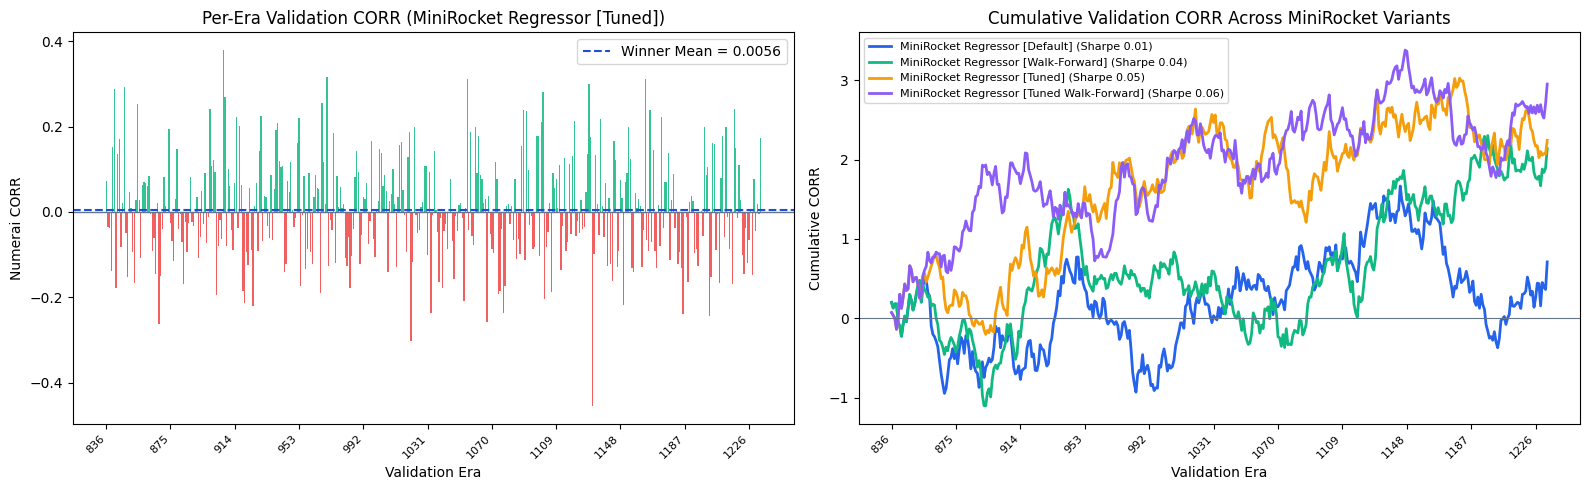

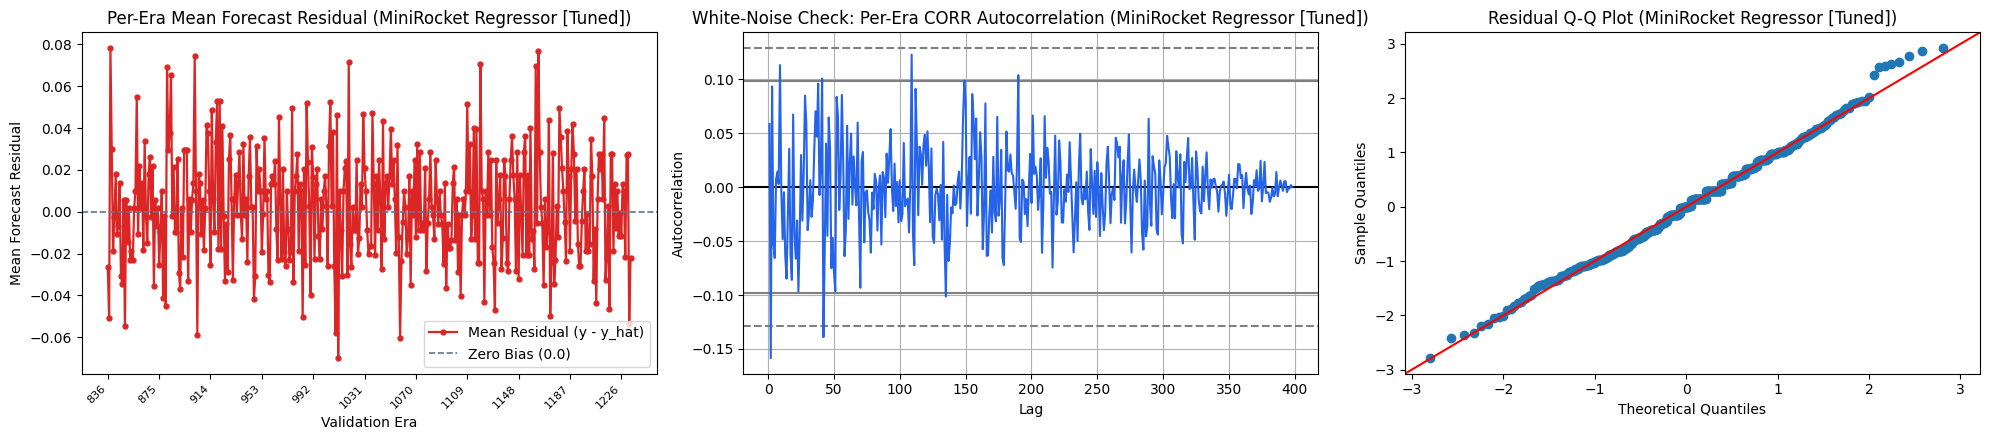

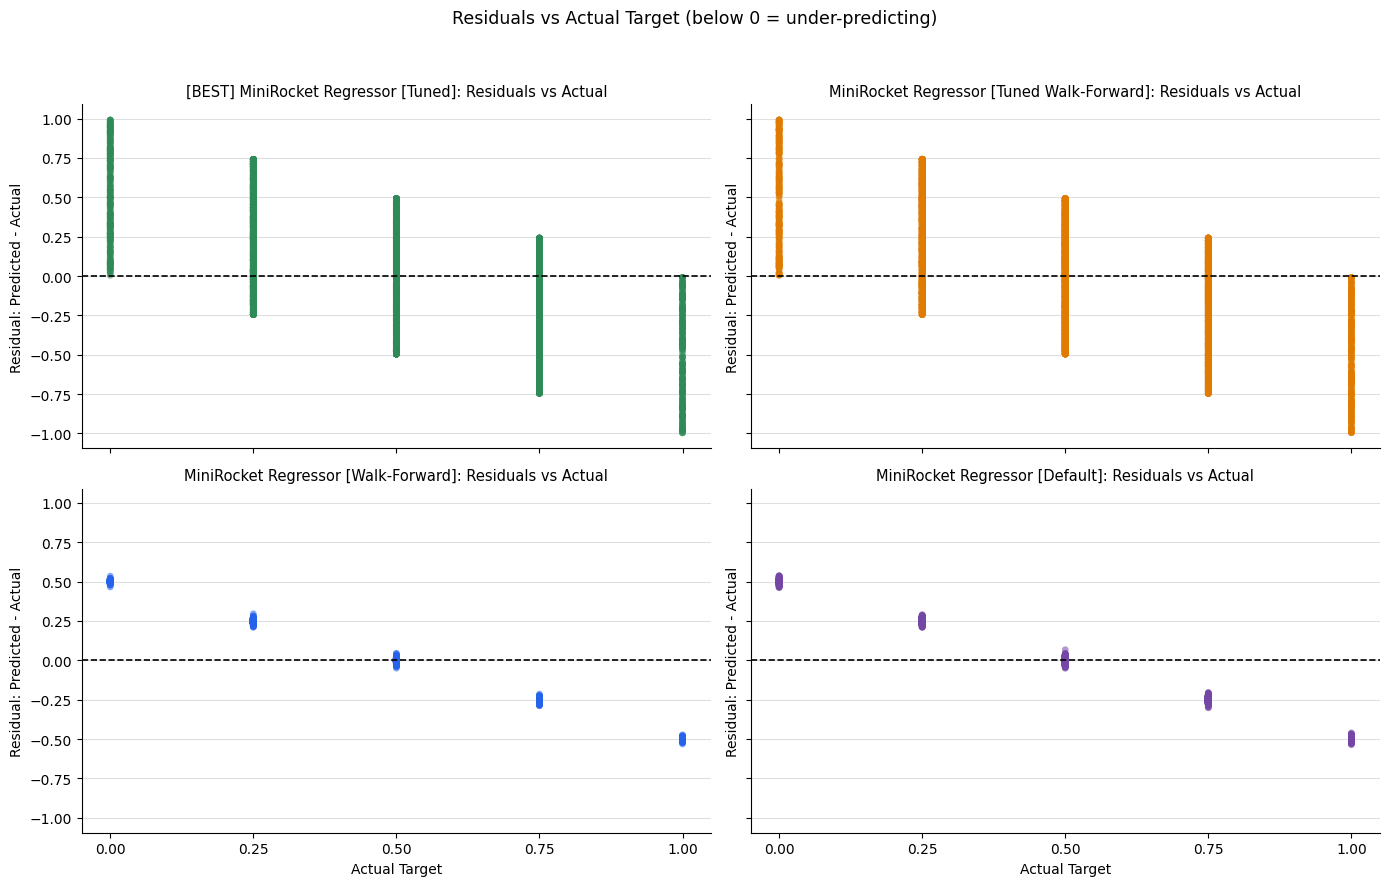

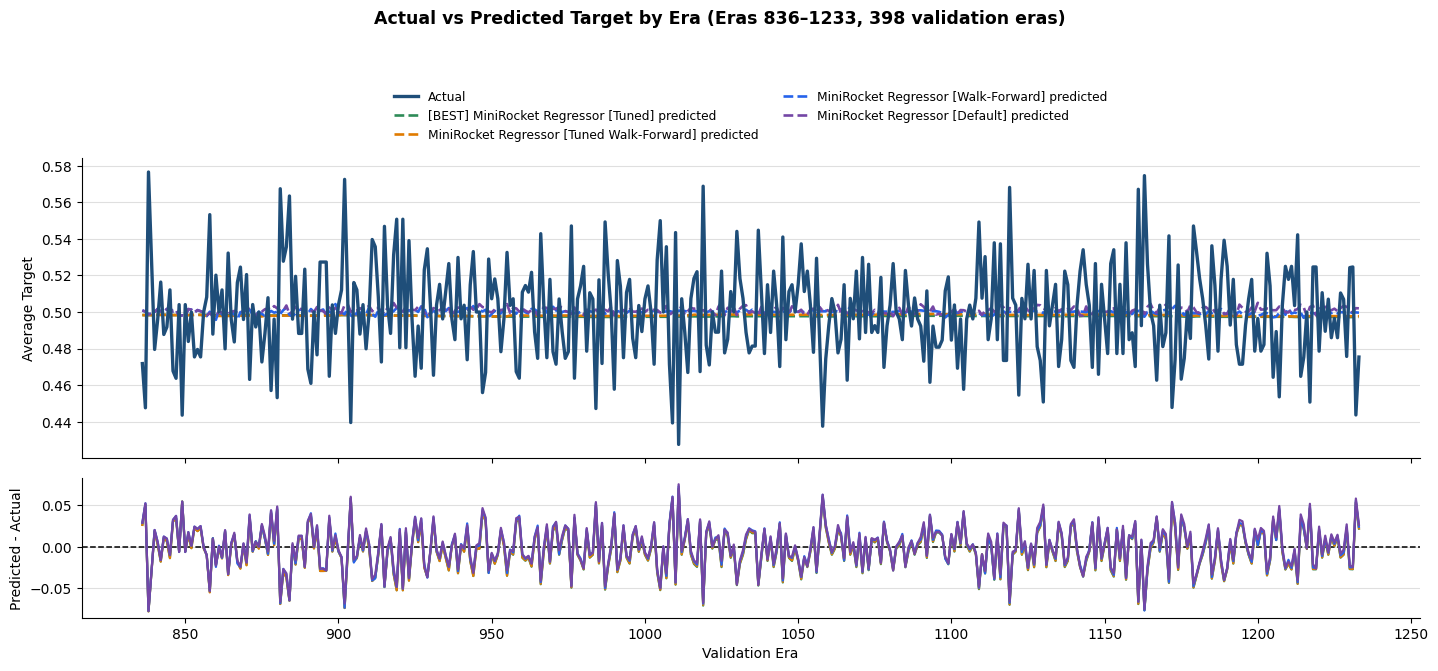

In [15]:
era_positions = np.arange(len(best_validation_era_corrs))
tick_step = max(1, len(best_validation_era_corrs) // 10)
tick_labels = best_validation_era_corrs.index.astype(str)[::tick_step]
line_colors = ['#2563eb', '#10b981', '#f59e0b', '#8b5cf6']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
ax.bar(
    era_positions,
    best_validation_era_corrs.to_numpy(),
    color=['#10b981' if era_corr >= 0 else '#ef4444' for era_corr in best_validation_era_corrs.to_numpy()],
    alpha=0.85,
)
ax.axhline(0.0, color='#64748b', linewidth=1.0)
ax.axhline(best_validation_corr, color='#1d4ed8', linestyle='--', linewidth=1.5, label=f'Winner Mean = {best_validation_corr:.4f}')
ax.set_xticks(era_positions[::tick_step])
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
ax.set_xlabel('Validation Era')
ax.set_ylabel('Numerai CORR')
ax.set_title(f'Per-Era Validation CORR ({best_variant_name})')
ax.legend()

ax = axes[1]
for color_index, (variant_name, result) in enumerate(model_results.items()):
    line_color = line_colors[color_index % len(line_colors)]
    ax.plot(
        era_positions,
        result['validation_era_corrs'].cumsum().to_numpy(),
        color=line_color,
        linewidth=2.0,
        label=f"{variant_name} (Sharpe {result['validation_sharpe']:.2f})",
    )
ax.axhline(0.0, color='#64748b', linewidth=0.8)
ax.set_xticks(era_positions[::tick_step])
ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
ax.set_xlabel('Validation Era')
ax.set_ylabel('Cumulative CORR')
ax.set_title('Cumulative Validation CORR Across MiniRocket Variants')
ax.legend(fontsize=8)

plt.tight_layout()
if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(results_dir / f'{timestamp}_{experiment_name}_era_perf.png', dpi=140)
    comparison_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_comparison.csv', index=False)
if export_diagnostics or save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    diagnostics_parquet_path = export_diagnostics_predictions(
        val_diag_meta,
        model_results[best_variant_name]['validation_preds'],
        results_dir / 'validation_predictions.parquet',
        era_col=ERA_COL,
    )
    print('Exported Numerai Diagnostics predictions Parquet (MMC & FNC):', diagnostics_parquet_path)
plt.show()

# Brownlee Residual, White-Noise & Tail-Normality Diagnostics (Per-Era Mean Residual + Era CORR Autocorrelation + Residual Q-Q Plot)
winner_val_preds = np.asarray(model_results[best_variant_name]['validation_preds'], dtype=np.float64).ravel()
winner_residuals = pd.Series(y_validation.to_numpy(dtype=np.float64) - winner_val_preds, index=validation_eras.index)
per_era_mean_residuals = winner_residuals.groupby(validation_eras, sort=True).mean()

fig_res, axes_res = plt.subplots(1, 3, figsize=(20, 4.5))
axes_res[0].plot(era_positions, per_era_mean_residuals.to_numpy(), color='#dc2626', marker='o', markersize=3.5, linewidth=1.6, label='Mean Residual (y - y_hat)')
axes_res[0].axhline(0.0, color='#64748b', linestyle='--', linewidth=1.2, label='Zero Bias (0.0)')
axes_res[0].set_xticks(era_positions[::tick_step])
axes_res[0].set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=8)
axes_res[0].set_xlabel('Validation Era')
axes_res[0].set_ylabel('Mean Forecast Residual')
axes_res[0].set_title(f'Per-Era Mean Forecast Residual ({best_variant_name})')
axes_res[0].legend()

if len(best_validation_era_corrs) >= 2:
    autocorrelation_plot(best_validation_era_corrs, ax=axes_res[1], color='#2563eb')
axes_res[1].set_title(f'White-Noise Check: Per-Era CORR Autocorrelation ({best_variant_name})')

if len(per_era_mean_residuals) >= 3:
    qqplot(per_era_mean_residuals.to_numpy(dtype=np.float64), line='45', fit=True, ax=axes_res[2])
axes_res[2].set_title(f'Residual Q-Q Plot ({best_variant_name})')
plt.tight_layout()
if save_results:
    plt.savefig(results_dir / f'{timestamp}_{experiment_name}_residual_white_noise.png', dpi=140)
plt.show()

# Residual Diagnostics (Residuals vs Actual + Actual vs Predicted by Era)
ordered_res_candidates = [best_variant_name] + [
    variant_name for variant_name in comparison_df['variant'].tolist() if variant_name != best_variant_name
]
residual_models = {
    variant_name: model_results[variant_name]['validation_preds']
    for variant_name in ordered_res_candidates
    if variant_name in model_results
}
residual_save_prefix = (
    results_dir / f'{timestamp}_{experiment_name}_residual_diagnostics'
    if save_results
    else None
)
residual_summary_df = plot_residual_diagnostics(
    y_validation,
    residual_models,
    validation_eras,
    best_variant_name=best_variant_name,
    max_models=4,
    random_state=random_state,
    save_prefix=residual_save_prefix,
)

MiniRocket Fitted Summary | backend=numpy | input_mode=ticker_sequence | channels=8 | seq_len=24 | rocket_features=84 | head=ridge (alpha=1242)
Top 20 MiniRocket PPV Kernels by |Weight|:


,rocket_feature,kernel_id,dilation,bias,coef,abs_coef,ppv_mean,ppv_std
0,k34_d1_f34,34,1,0.0,-0.003831,0.003831,0.173361,1.0
1,k36_d1_f36,36,1,0.0,0.003283,0.003283,0.143898,1.0
2,k08_d1_f8,8,1,0.0,0.002943,0.002943,0.140429,1.0
3,k54_d1_f54,54,1,0.0,0.002877,0.002877,0.236811,1.0
4,k72_d1_f72,72,1,0.0,0.002423,0.002423,0.150674,1.0
5,k80_d1_f80,80,1,0.0,0.002387,0.002387,0.213650,1.0
6,k66_d1_f66,66,1,0.0,0.002309,0.002309,0.211332,1.0
7,k82_d1_f82,82,1,0.0,0.002154,0.002154,0.151049,1.0
8,k62_d1_f62,62,1,0.0,0.001878,0.001878,0.116854,1.0
9,k52_d1_f52,52,1,0.0,0.001589,0.001589,0.145255,1.0


Top 20 Input Channels by Aggregated MiniRocket Kernel Weight:


,feature,kernel_weight_sum,train_corr
0,pca_comp_4,0.016890,0.026292
1,pca_comp_1,0.010849,0.019735
2,pca_comp_12,0.010519,0.020511
3,pca_comp_14,0.006894,-0.032042
4,pca_comp_0,0.004805,0.020239
5,pca_comp_15,0.004395,-0.036900
6,pca_comp_3,0.004369,-0.017982
7,pca_comp_10,0.002457,0.015352


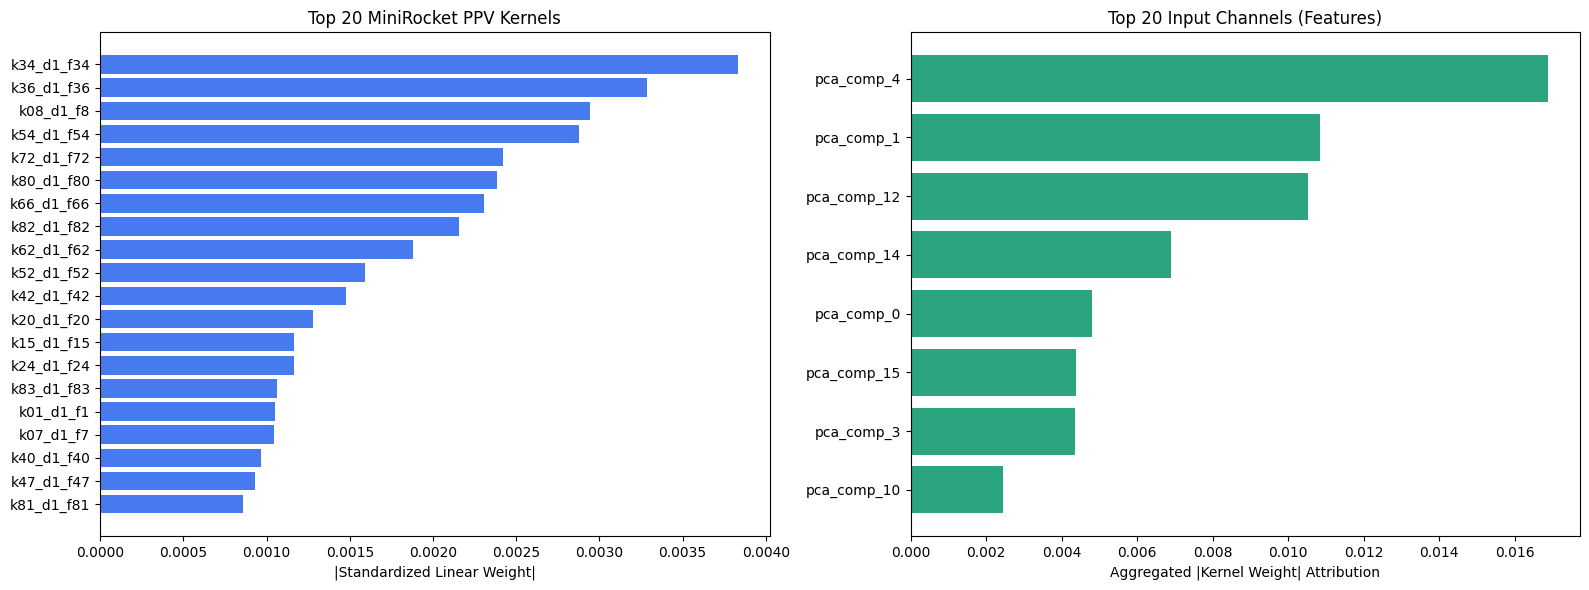

In [16]:
fitted_mr = fitted_default_models[model_name].named_steps['estimator']
top_kernels_df = fitted_mr.kernel_importance_df_.head(20)
top_channels_df = fitted_mr.channel_importance_df_.head(20)
print(
    f'MiniRocket Fitted Summary | backend={fitted_mr.active_backend_} | '
    f'input_mode={fitted_mr.active_input_mode_} | channels={fitted_mr.n_channels_in_} | '
    f'seq_len={fitted_mr.seq_len_in_} | rocket_features={fitted_mr.n_rocket_features_} | '
    f'head={fitted_mr.active_head_type_} (alpha={fitted_mr.chosen_alpha_:.4g})'
)
print('Top 20 MiniRocket PPV Kernels by |Weight|:')
display(top_kernels_df)
print('Top 20 Input Channels by Aggregated MiniRocket Kernel Weight:')
display(top_channels_df)

if plt is not None and len(top_kernels_df) and len(top_channels_df):
    fig_imp, axes_imp = plt.subplots(1, 2, figsize=(16, 6))
    plot_k = top_kernels_df.sort_values('abs_coef', ascending=True)
    axes_imp[0].barh(plot_k['rocket_feature'], plot_k['abs_coef'], color='#2563eb', alpha=0.85)
    axes_imp[0].set_xlabel('|Standardized Linear Weight|')
    axes_imp[0].set_title('Top 20 MiniRocket PPV Kernels')

    plot_c = top_channels_df.sort_values('kernel_weight_sum', ascending=True)
    axes_imp[1].barh(plot_c['feature'], plot_c['kernel_weight_sum'], color='#059669', alpha=0.85)
    axes_imp[1].set_xlabel('Aggregated |Kernel Weight| Attribution')
    axes_imp[1].set_title('Top 20 Input Channels (Features)')
    plt.tight_layout()
    if save_results:
        results_dir.mkdir(parents=True, exist_ok=True)
        plt.savefig(results_dir / f'{timestamp}_{experiment_name}_minirocket_importance.png', dpi=140)
    plt.show()


In [17]:
for cur_model_name, cv_results_df in cv_results_by_model.items():
    print(f'Top CV candidates for {cur_model_name}:')
    display(cv_results_df.head(10))
    if save_results:
        results_dir.mkdir(parents=True, exist_ok=True)
        cv_results_path = results_dir / f'{timestamp}_{experiment_name}_{search_mode}_cv.csv'
        cv_results_df.to_csv(cv_results_path, index=False)
        print('Saved CV results CSV:', cv_results_path)

Top CV candidates for MiniRocket Regressor:


,candidate_id,rank_test_score,mean_test_score,score_version,end_capital,total_profit,total_return_pct,money_drawdown_pct,mean_directional_accuracy_pct,mean_accurate_pct,...,max_channels,max_dilations_per_kernel,pad_mode,prediction_transform,recency_decay,seq_len,standardize_features,top_k,walk_forward_step_eras,walk_forward_window
0,0,1,-0.063986,v1_skepta,997.15,-2.85,-0.28,-4.59,49.67,5.54,...,8,4,first,era_rank,0.00466,24,False,None,None,sliding


Saved CV results CSV: /kaggle/working/results_numerai_v6.0_all_eras_stride4_minirocket_target_bayes/20261125_050727_numerai_v6.0_all_eras_stride4_minirocket_bayes_cv.csv


## Error-Direction Envelope Analysis (All Variants — Best Highlighted)

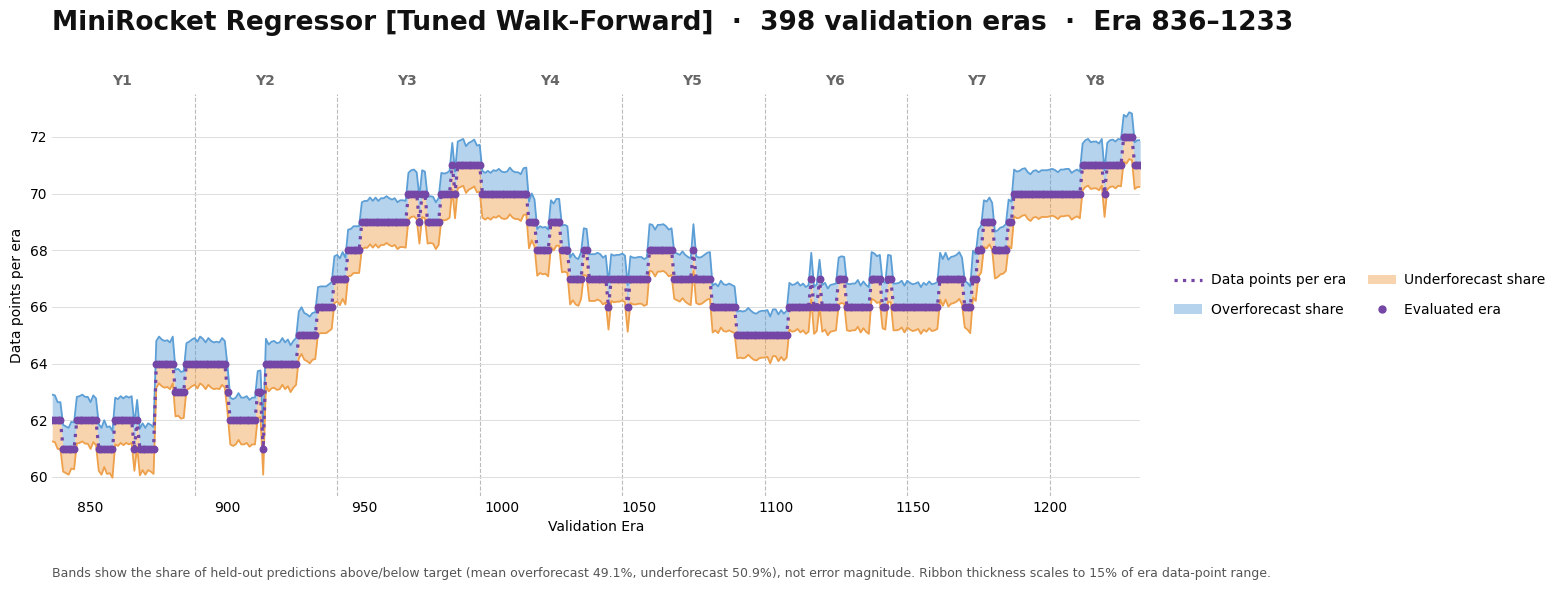

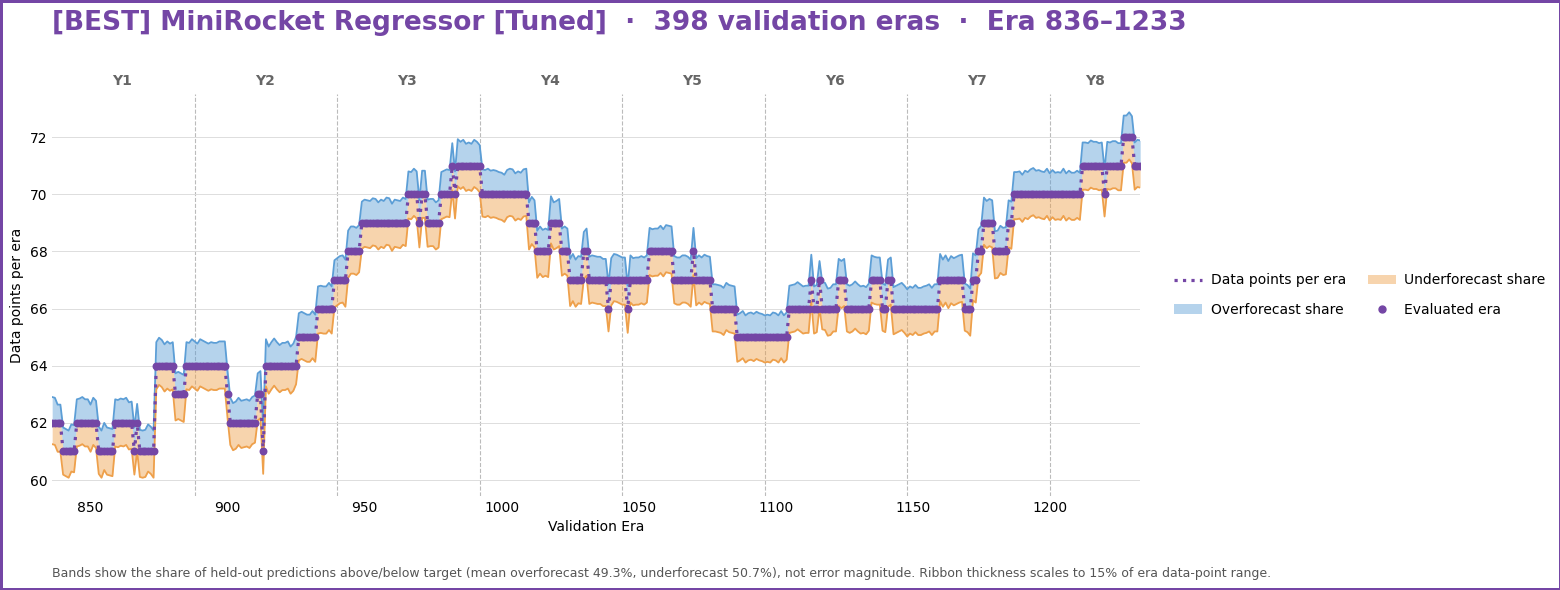

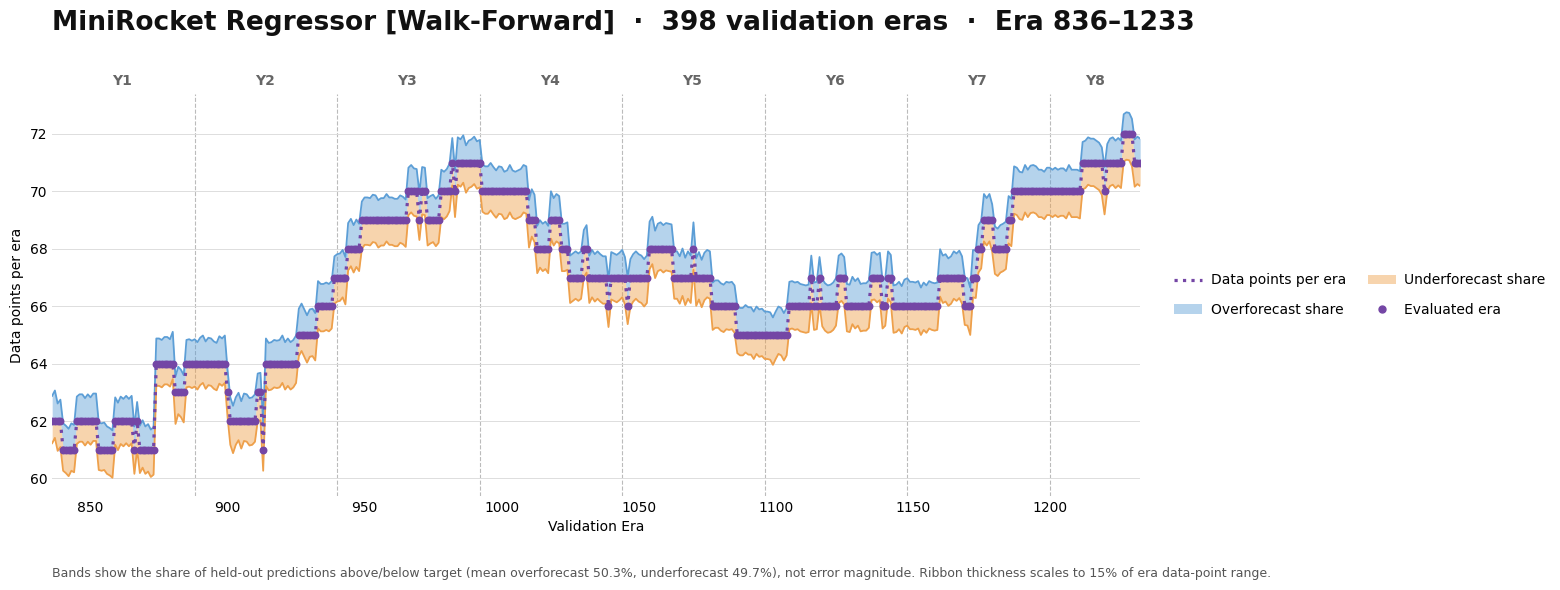

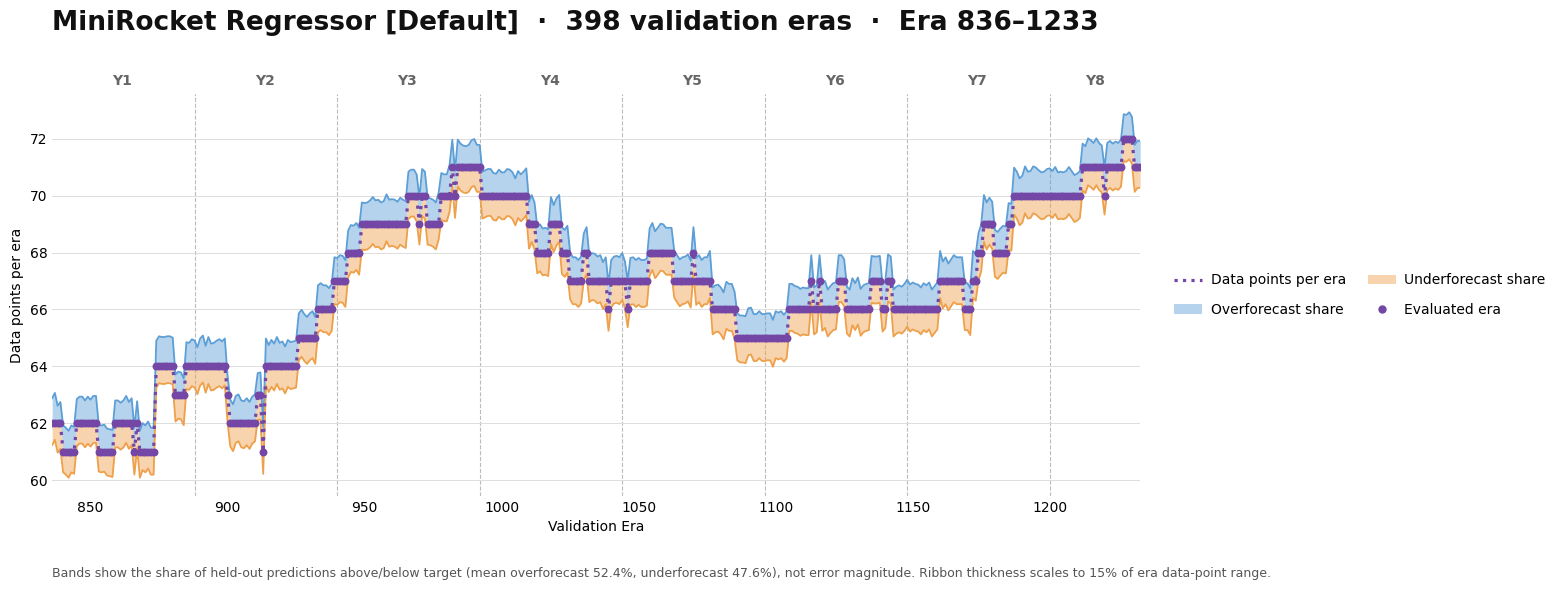

Best Model Envelope Summary (MiniRocket Regressor [Tuned]):


,data_points,under_share,over_share,mae,mean_residual,is_interpolated
era,,,,,,
836,62,0.451613,0.548387,0.310581,0.026542,False
837,62,0.467742,0.532258,0.316098,0.050736,False
838,62,0.612903,0.387097,0.317888,-0.078297,False
839,62,0.612903,0.387097,0.344423,-0.029909,False
840,61,0.491803,0.508197,0.258843,0.018940,False
841,61,0.524590,0.475410,0.243089,0.002547,False
842,61,0.557377,0.442623,0.307622,-0.017945,False
843,61,0.426230,0.573770,0.297070,0.010744,False
844,61,0.442623,0.557377,0.275823,0.006645,False


In [18]:
envelope_dfs = {}
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    envelope_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_error_envelope.png'
        if save_results
        else None
    )
    envelope_dfs[variant_name] = plot_era_error_envelope(
        y_validation,
        model_results[variant_name]['validation_preds'],
        validation_eras,
        title=variant_name,
        band_size=0.15,
        is_best=is_best_variant,
        save_path=envelope_save_path,
    )

envelope_df = envelope_dfs[best_variant_name]
print(f'Best Model Envelope Summary ({best_variant_name}):')
display(envelope_df.head(10))

## AFML Backtest Overfitting, Risk & Numerai Forum #1454 Diagnostics
Summarizes **Era Consistency (`CORR > 0.002`)**, **Lo (2002) autocorrelation-adjusted Sharpe**, **PSR**, **ONC-Clustered $E[K]$ DSR & Šidák FWER $\alpha_K$**, **MinTRL**, **CSCV Probability of Backtest Overfitting (PBO)**, **Feature Neutral Correlation (FNC)**, **Time under Water (TuW)**, **Return Concentration (HHI)**, and **AFML Ch. 15 Strategy Failure Probability**.

In [19]:
afml_diag_rows = []
for variant_name, res_entry in model_results.items():
    base_key = variant_name.split(' [')[0]
    cv_df_ref = cv_results_by_model.get(base_key)
    v_trials_mat = cv_df_ref.attrs.get('trials_era_corrs_df') if cv_df_ref is not None else None
    v_trial_srs = (
        cv_df_ref['mean_sharpe'].dropna().to_numpy(dtype=np.float64)
        if (cv_df_ref is not None and 'mean_sharpe' in cv_df_ref.columns and len(cv_df_ref) > 0 and '[Tuned' in variant_name)
        else [res_entry['validation_sharpe']]
    )
    afml_diag_rows.append(
        summarize_afml_backtest_diagnostics(
            res_entry['validation_era_corrs'],
            trial_srs=v_trial_srs,
            trials_matrix=v_trials_mat if '[Tuned' in variant_name else None,
            y_true=y_validation,
            y_pred=res_entry['validation_preds'],
            features_df=X_validation,
            feature_columns=feature_columns,
            eras=validation_eras,
            label=variant_name,
            random_state=random_state,
        )
    )
afml_diagnostics_df = pd.DataFrame(afml_diag_rows)
print('AFML Backtest Risk, Multiple-Testing (ONC-Clustered DSR / PBO) & Numerai Forum #1454 Diagnostics:')
display(afml_diagnostics_df)
if save_results:
    results_dir.mkdir(parents=True, exist_ok=True)
    afml_diagnostics_df.to_csv(results_dir / f'{timestamp}_{experiment_name}_afml_diagnostics.csv', index=False)


AFML Backtest Risk, Multiple-Testing (ONC-Clustered DSR / PBO) & Numerai Forum #1454 Diagnostics:


,variant,n_eras,mean_corr,positive_era_pct,era_consistency_pct,numerai_sharpe,lo_adjusted_sharpe,psr,dsr,effective_n_trials_onc,...,pbo_cscv,fnc_mean,fnc_sharpe,corr_drawdown,tuw_max_eras,tuw_max_years,hhi_pos,hhi_neg,hhi_time,strategy_fail_prob
0,MiniRocket Regressor [Default],398,0.0018,49.50,47.74,0.0134,0.0142,0.6053,0.6053,1.0,...,NaN,0.0,0.0,2.0372,131,2.52,0.0029,0.0023,0.0007,0.9925
1,MiniRocket Regressor [Walk-Forward],398,0.0054,50.25,49.25,0.0443,0.0440,0.8117,0.8117,1.0,...,NaN,0.0,0.0,1.9933,196,3.77,0.0024,0.0025,0.0016,0.9539
2,MiniRocket Regressor [Tuned],398,0.0056,50.50,49.75,0.0461,0.0490,0.8216,0.8216,1.0,...,NaN,0.0,0.0,1.4283,108,2.08,0.0030,0.0027,0.0017,0.9462
3,MiniRocket Regressor [Tuned Walk-Forward],398,0.0074,53.27,52.26,0.0621,0.0646,0.8904,0.8904,1.0,...,NaN,0.0,0.0,1.6062,89,1.71,0.0027,0.0038,0.0011,0.8813


## NumerAPI v6.0 Dataset Discovery & True MMC vs BMC Proxy Check
Lists every published `v6.0/` file via `NumerAPI`, checks whether true `meta_model.parquet` exists, and falls back cleanly to `validation_benchmark_models.parquet` labeled **BMC proxy (benchmark, NOT true MMC)**.

In [20]:
v6_contrib_info = discover_and_fetch_v6_meta_or_benchmark(
    data_version=data_version,
    data_folder=data_folder,
    workspace_root=workspace_root,
    auto_download=True,
    verbose=True,
)

=== NumerAPI Dataset Discovery (v6.0) ===
All v6.0 files found (14):
  - v6.0/features.json
  - v6.0/live.parquet
  - v6.0/live_benchmark_models.parquet
  - v6.0/live_example_preds.csv
  - v6.0/live_example_preds.parquet
  - v6.0/live_neutralizer.parquet
  - v6.0/train.parquet
  - v6.0/train_benchmark_models.parquet
  - v6.0/train_neutralizer.parquet
  - v6.0/validation.parquet
  - v6.0/validation_benchmark_models.parquet
  - v6.0/validation_example_preds.csv
  - v6.0/validation_example_preds.parquet
  - v6.0/validation_neutralizer.parquet

Filtered (meta, benchmark, neutralizer, example) (10):
  - v6.0/live_benchmark_models.parquet
  - v6.0/live_example_preds.csv
  - v6.0/live_example_preds.parquet
  - v6.0/live_neutralizer.parquet
  - v6.0/train_benchmark_models.parquet
  - v6.0/train_neutralizer.parquet
  - v6.0/validation_benchmark_models.parquet
  - v6.0/validation_example_preds.csv
  - v6.0/validation_example_preds.parquet
  - v6.0/validation_neutralizer.parquet

[MMC Status] No 

## Simulated Numerai Staking P&L Dashboard (£)

Active Staking Basis: BMC proxy (benchmark, NOT true MMC)
  -> Reason: No v6.0 meta_model.parquet published yet, so true MMC / NMMC cannot be computed in backtest. Falling back to validation_benchmark_models.parquet (saved at /kaggle/input/notebooks/svendaj/numerai-data-v6-0-unity/v6.0/validation_benchmark_models.parquet) to compute BMC proxy (benchmark, NOT true MMC).


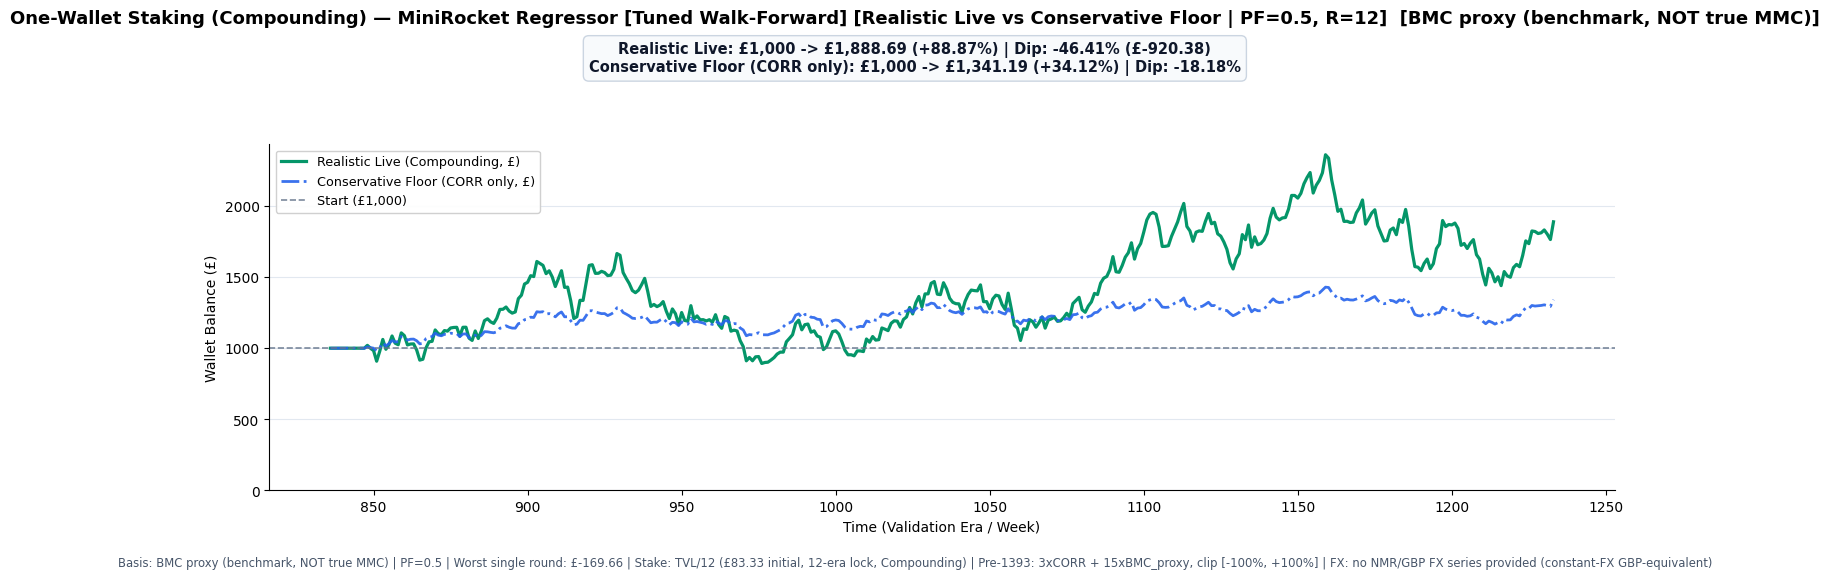

MiniRocket Regressor [Tuned Walk-Forward] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £1,888.69 (+88.87%, Dip -46.41%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,341.19 (+34.12%, Dip -18.18%) | Basis: BMC proxy (benchmark, NOT true MMC)


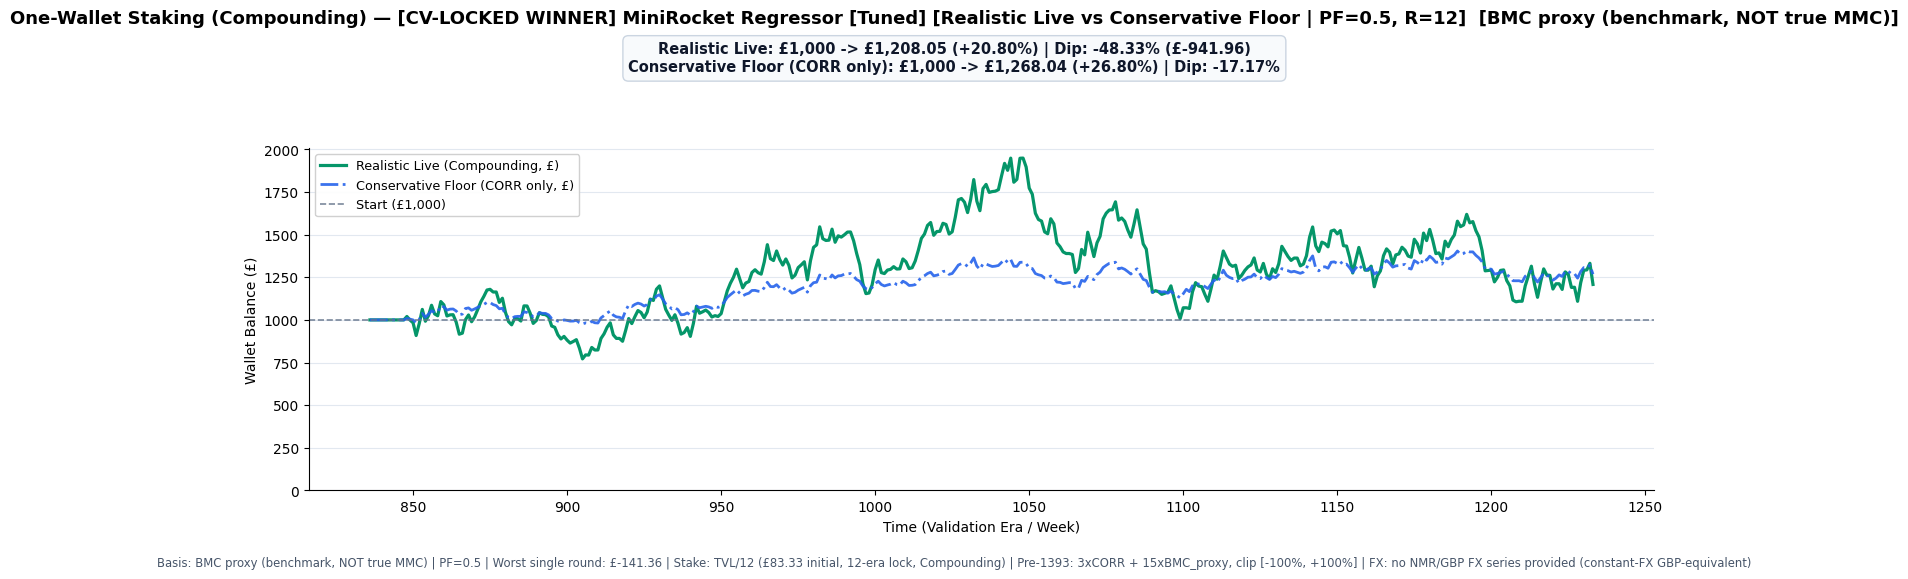

[CV-LOCKED WINNER] MiniRocket Regressor [Tuned] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £1,208.05 (+20.80%, Dip -48.33%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,268.04 (+26.80%, Dip -17.17%) | Basis: BMC proxy (benchmark, NOT true MMC)


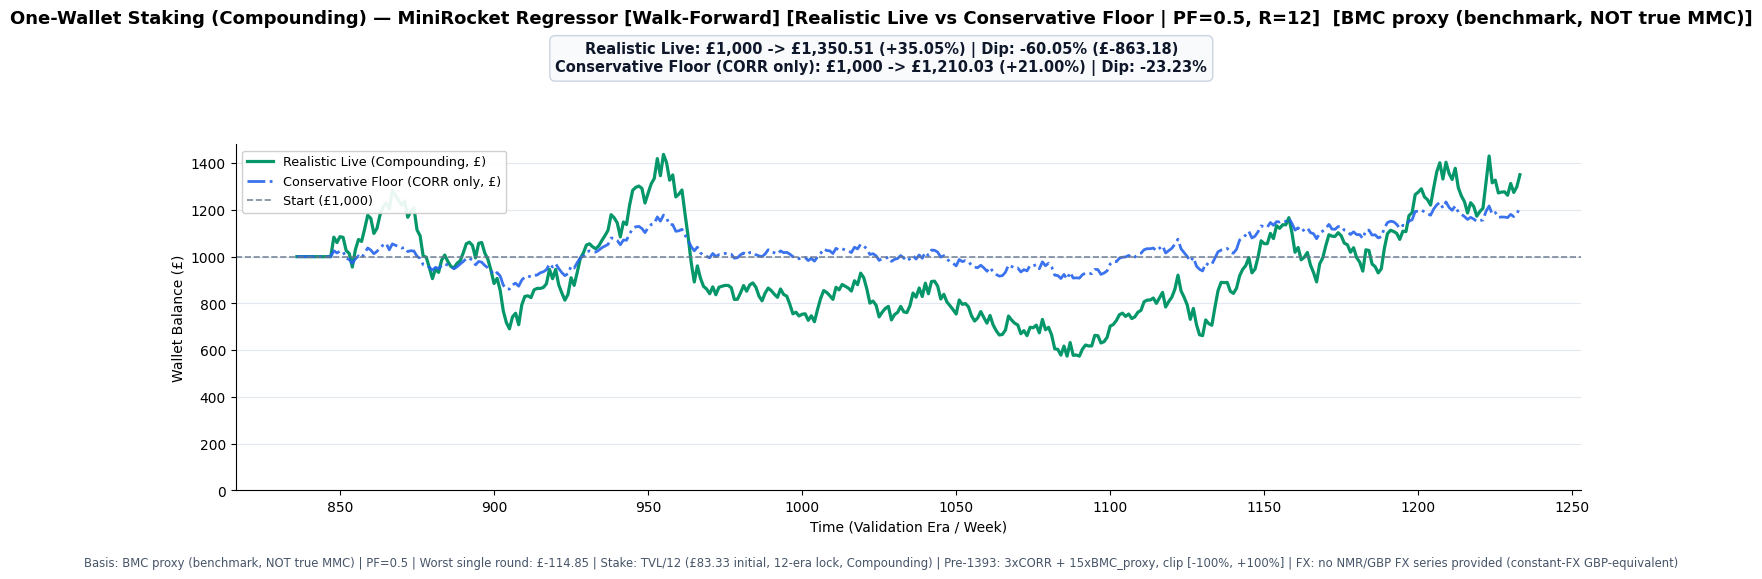

MiniRocket Regressor [Walk-Forward] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £1,350.51 (+35.05%, Dip -60.05%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,210.03 (+21.00%, Dip -23.23%) | Basis: BMC proxy (benchmark, NOT true MMC)


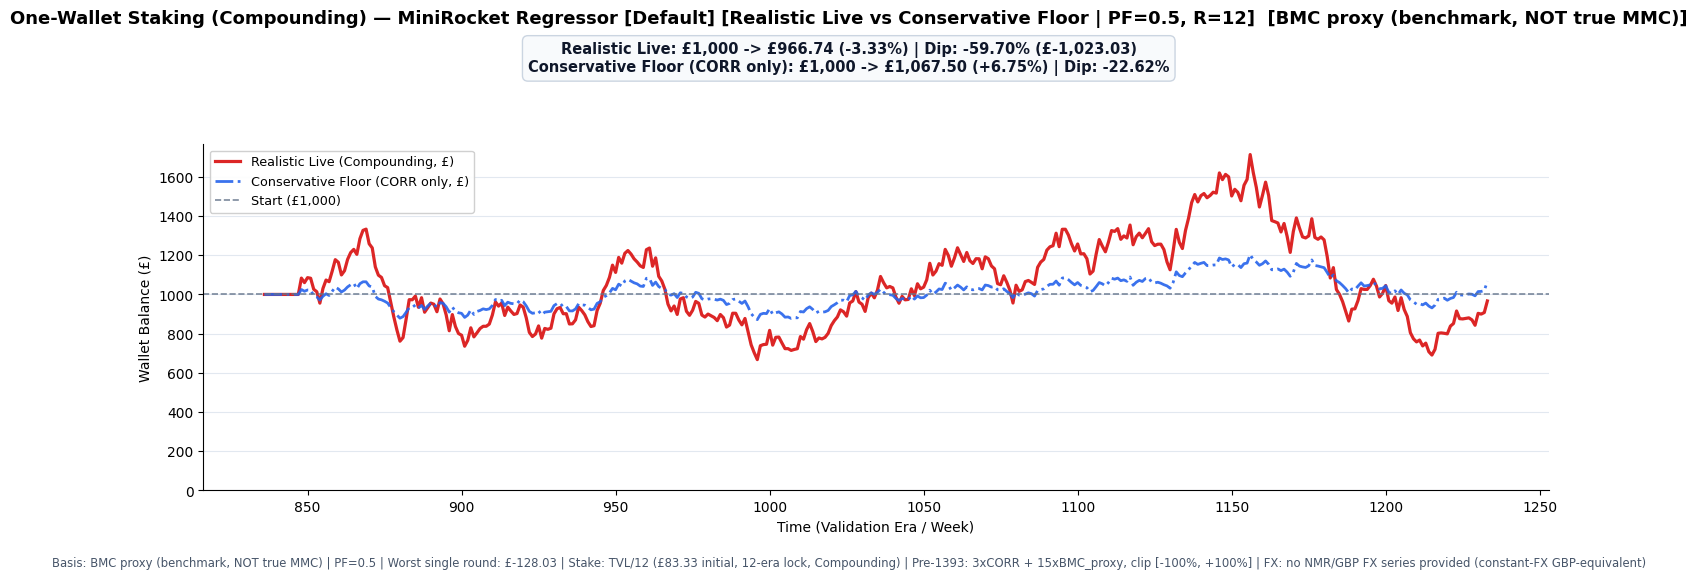

MiniRocket Regressor [Default] | Realistic Live (PF=0.5, 0.5x BMC, R=12): £966.74 (-3.33%, Dip -59.70%) | Conservative Floor (CORR only, PF=0.5, R=12): £1,067.50 (+6.75%, Dip -22.62%) | Basis: BMC proxy (benchmark, NOT true MMC)

Dual-Scenario Realistic Live Staking Table (Conservative Floor [CORR only, PF=0.5, R=12] vs Realistic Live [CORR + 0.5x BMC proxy, PF=0.5, R=12]):


,variant,conservative_end_gbp,conservative_return_pct,conservative_worst_dip_pct,conservative_mc_p_profit_pct,realistic_live_end_gbp,realistic_live_return_pct,realistic_live_worst_dip_pct,realistic_live_mc_p_profit_pct,realistic_live_mc_median_gbp,payout_factor,bmc_haircut,concurrent_rounds
0,MiniRocket Regressor [Tuned Walk-Forward],1341.19,34.12,-18.18,86.4,1888.69,88.87,-46.41,85.2,2548.58,0.5,0.5,12
1,MiniRocket Regressor [Tuned],1268.04,26.80,-17.17,80.4,1208.05,20.80,-48.33,59.0,1189.47,0.5,0.5,12
2,MiniRocket Regressor [Walk-Forward],1210.03,21.00,-23.23,75.8,1350.51,35.05,-60.05,63.6,1379.05,0.5,0.5,12
3,MiniRocket Regressor [Default],1067.50,6.75,-22.62,57.6,966.74,-3.33,-59.70,45.0,858.32,0.5,0.5,12


In [21]:
val_mmc_df = val_diag_meta.assign(**{TARGET_COL: y_validation.to_numpy(dtype=np.float32)})
staking_basis_label = v6_contrib_info['basis_label']
staking_is_proxy = bool(v6_contrib_info['mmc_is_proxy'])
print(f"Active Staking Basis: {staking_basis_label}")
print(f"  -> Reason: {v6_contrib_info['reason']}")

stake_pnl_by_variant = {}
variant_era_mmc_by_variant = {}
live_scenarios_by_variant = {}
staking_summary_rows = []
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    variant_era_corrs = model_results[variant_name]['validation_era_corrs']
    variant_era_contrib = compute_per_era_mmc(
        val_mmc_df,
        model_results[variant_name]['validation_preds'],
        meta_model_path=v6_contrib_info['meta_model_path'],
        benchmark_path=v6_contrib_info['benchmark_path'],
        is_benchmark_proxy=staking_is_proxy,
        era_col=ERA_COL,
        target_col=TARGET_COL,
    )
    variant_era_mmc_by_variant[variant_name] = variant_era_contrib

    live_scenarios_by_variant[variant_name] = simulate_live_staking_scenarios(
        variant_era_corrs,
        per_era_mmc=variant_era_contrib,
        mmc_is_proxy=staking_is_proxy,
        total_capital=1000.0,
        settlement_rounds=12,
        weekly_concurrent_rounds=12,
        conservative_payout_factor=0.5,
        live_payout_factor=0.5,
        bmc_proxy_haircut=0.5,
        n_sims=500,
        block_size=12,
        random_state=random_state,
        title=variant_name,
        era_dates=val_era_dates,
    )

    title_label = f'[CV-LOCKED WINNER] {variant_name}' if is_best_variant else variant_name
    pnl_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_stake_pnl_dashboard.png'
        if save_results
        else None
    )
    haircutted_contrib = (
        pd.Series(variant_era_contrib, dtype=np.float64) * (0.5 if staking_is_proxy else 1.0)
        if variant_era_contrib is not None
        else None
    )
    if haircutted_contrib is not None:
        haircutted_contrib.name = 'bmc_proxy' if staking_is_proxy else 'mmc'
    stake_pnl_by_variant[variant_name] = plot_stake_pnl_dashboard(
        variant_era_corrs,
        per_era_mmc=haircutted_contrib,
        mmc_is_proxy=staking_is_proxy,
        conservative_pnl=live_scenarios_by_variant[variant_name]['conservative_floor']['pnl'],
        title=f'{title_label} [Realistic Live vs Conservative Floor | PF=0.5, R=12]',
        total_capital=1000.0,
        concurrent_rounds=12,
        settlement_rounds=12,
        payout_factor=0.5,
        payout_rule='auto',
        staking_mode='compound',
        era_dates=val_era_dates,
        save_path=pnl_save_path,
    )

    v_pnl = stake_pnl_by_variant[variant_name]
    c_pnl = live_scenarios_by_variant[variant_name]['conservative_floor']['pnl']
    mean_contrib = float(variant_era_contrib.mean()) if variant_era_contrib is not None and len(variant_era_contrib) > 0 else np.nan
    contrib_col_name = 'validation_bmc_proxy' if staking_is_proxy else 'validation_true_mmc'
    staking_summary_rows.append({
        'variant': variant_name,
        'staking_basis': v_pnl['score_basis'],
        'staking_mode': 'One-Wallet (Compounding, PF=0.5, R=12)',
        'validation_corr': round(float(variant_era_corrs.mean()), 4),
        contrib_col_name: round(mean_contrib, 4) if np.isfinite(mean_contrib) else np.nan,
        'start_capital': round(float(v_pnl['start_capital']), 2),
        'end_capital': round(float(v_pnl['end_capital']), 2),
        'total_return_pct': round(float(v_pnl['total_return_pct']), 2),
        'worst_dip_pct': round(float(v_pnl['money_drawdown_pct']), 2),
        'worst_dip_gbp': round(float(v_pnl['max_drawdown_gbp']), 2),
        'worst_round_gbp': round(float(v_pnl['worst_round_gbp']), 2),
    })
    print(
        f"{title_label} | Realistic Live (PF=0.5, 0.5x BMC, R=12): £{v_pnl['end_capital']:,.2f} ({v_pnl['total_return_pct']:+.2f}%, Dip {v_pnl['money_drawdown_pct']:.2f}%) | "
        f"Conservative Floor (CORR only, PF=0.5, R=12): £{c_pnl['end_capital']:,.2f} ({c_pnl['total_return_pct']:+.2f}%, Dip {c_pnl['money_drawdown_pct']:.2f}%) | "
        f"Basis: {v_pnl['score_basis']}"
    )

staking_comparison_df = pd.DataFrame(staking_summary_rows)
live_staking_scenarios_df = build_live_staking_scenarios_df(live_scenarios_by_variant)
comparison_df['staking_basis'] = comparison_df['variant'].map(
    staking_comparison_df.set_index('variant')['staking_basis']
)
if staking_is_proxy:
    comparison_df['validation_bmc_proxy'] = comparison_df['variant'].map(
        staking_comparison_df.set_index('variant')['validation_bmc_proxy']
    )
elif v6_contrib_info['basis_kind'] == 'true_mmc':
    comparison_df['validation_true_mmc'] = comparison_df['variant'].map(
        staking_comparison_df.set_index('variant')['validation_true_mmc']
    )
print('\nDual-Scenario Realistic Live Staking Table (Conservative Floor [CORR only, PF=0.5, R=12] vs Realistic Live [CORR + 0.5x BMC proxy, PF=0.5, R=12]):')
display(live_staking_scenarios_df)
best_stake_pnl = stake_pnl_by_variant[best_variant_name]

## Monte Carlo Block-Bootstrap Risk Analysis (£)

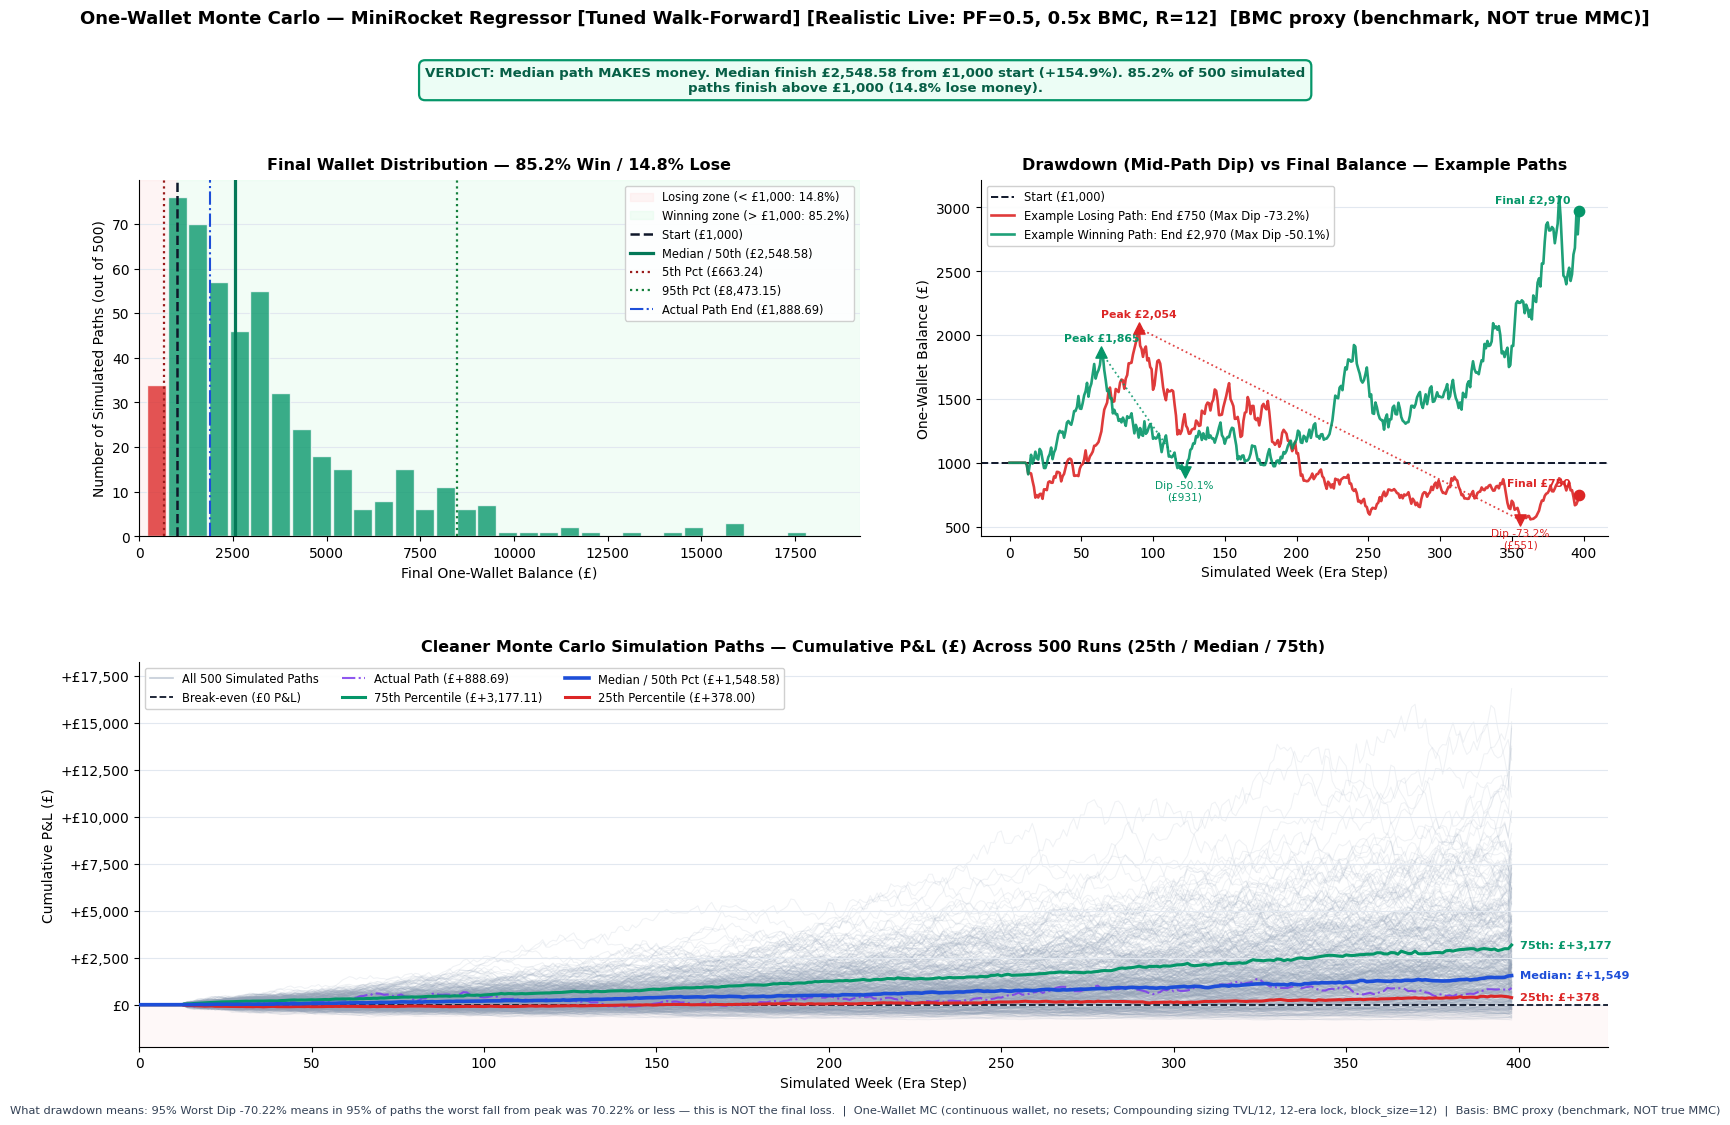

MiniRocket Regressor [Tuned Walk-Forward] — VERDICT: Median path MAKES money. Median finish £2,548.58 from £1,000 start (+154.9%). 85.2% of 500 simulated paths finish above £1,000 (14.8% lose money).

How to read Drawdown vs Final Balance (Plain English):
  • Drawdown is the biggest peak-to-trough dip DURING the journey — NOT your final profit or loss.
  • Worked example (Winning path with a drawdown): Start £1,000 -> rises to £1,200 peak -> dips to £1,100 (-8.3% drawdown from peak) -> recovers to £1,300. You still finish +£300 ABOVE £1,000 despite the dip.
  • Worked example (Losing path with a small drawdown): Start £1,000 -> drifts down to £955 (-4.5% dip) and ends at £984.81. A small drawdown still finishes BELOW £1,000 if it never recovers.
  • Median (50th) vs 95th percentile are DIFFERENT paths: Median = typical path; 95th = lucky top 5% of paths.
  • One-Wallet MC: Simulates ONE continuous wallet from start to finish over the full validation period with no resets.
  • Within-Wi

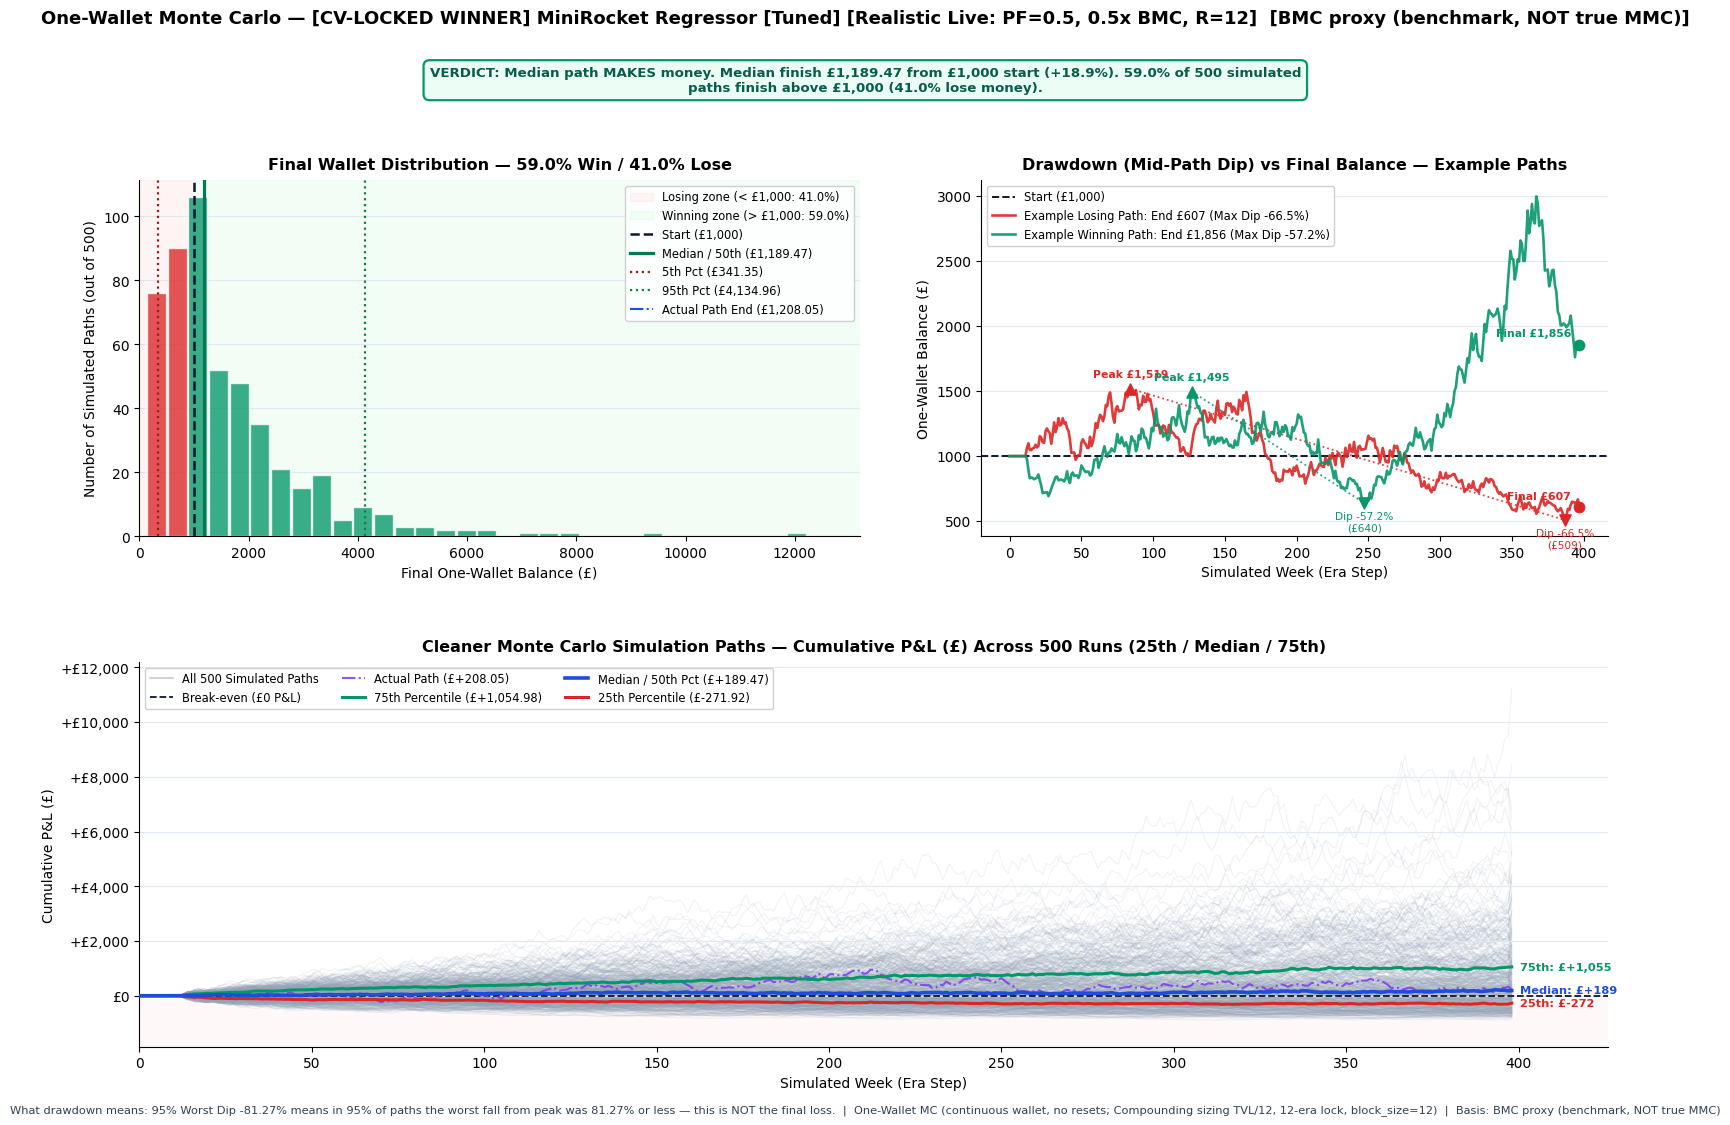

[CV-LOCKED WINNER] MiniRocket Regressor [Tuned] — VERDICT: Median path MAKES money. Median finish £1,189.47 from £1,000 start (+18.9%). 59.0% of 500 simulated paths finish above £1,000 (41.0% lose money).

[CV-LOCKED WINNER] MiniRocket Regressor [Tuned] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 59.0% (41.0% lose) | Median (50th): £1,189.47 (+18.9%) | 5th Pct: £341.35 | 95th Pct: £4,134.96 | 95% Worst Dip: -81.27% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -81.27% means in 95% of paths the worst fall from peak was 81.27% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=80.4% | Median=£1,272.39 | 95% Worst Dip=-36.27%


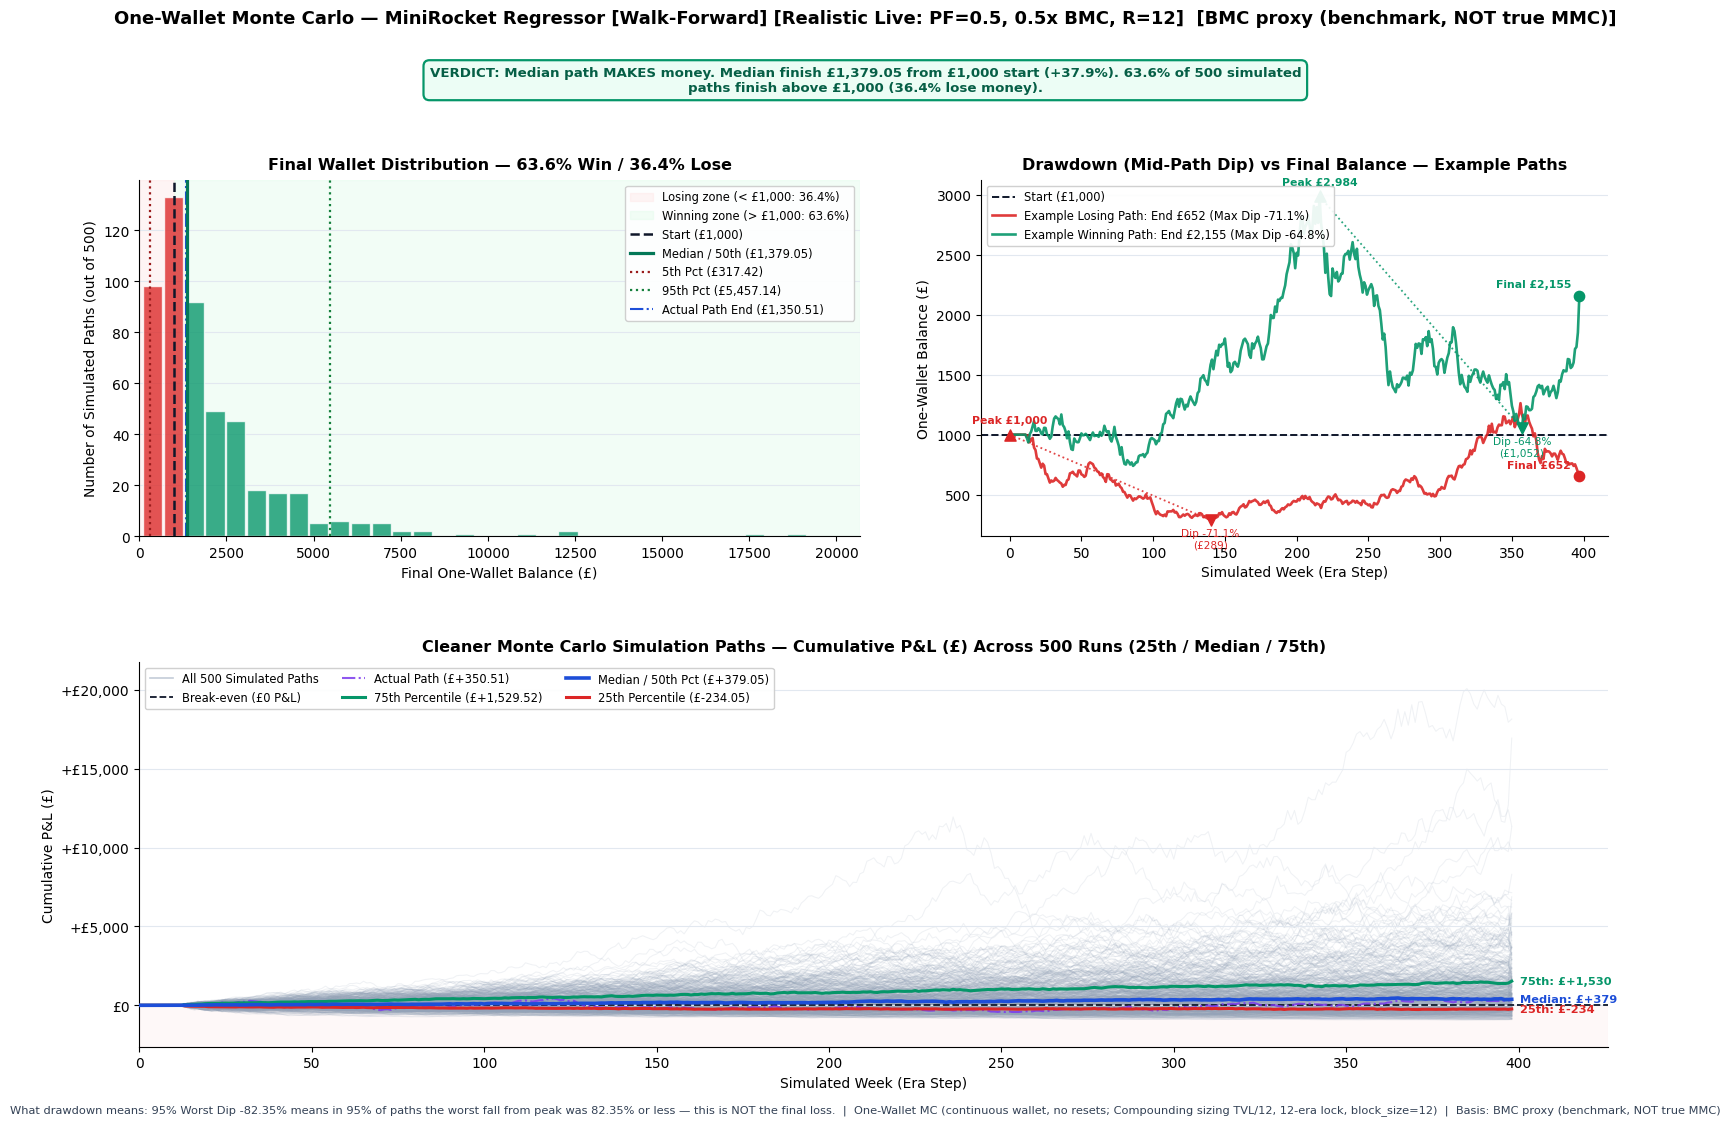

MiniRocket Regressor [Walk-Forward] — VERDICT: Median path MAKES money. Median finish £1,379.05 from £1,000 start (+37.9%). 63.6% of 500 simulated paths finish above £1,000 (36.4% lose money).

MiniRocket Regressor [Walk-Forward] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 63.6% (36.4% lose) | Median (50th): £1,379.05 (+37.9%) | 5th Pct: £317.42 | 95th Pct: £5,457.14 | 95% Worst Dip: -82.35% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -82.35% means in 95% of paths the worst fall from peak was 82.35% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=75.8% | Median=£1,228.66 | 95% Worst Dip=-41.06%


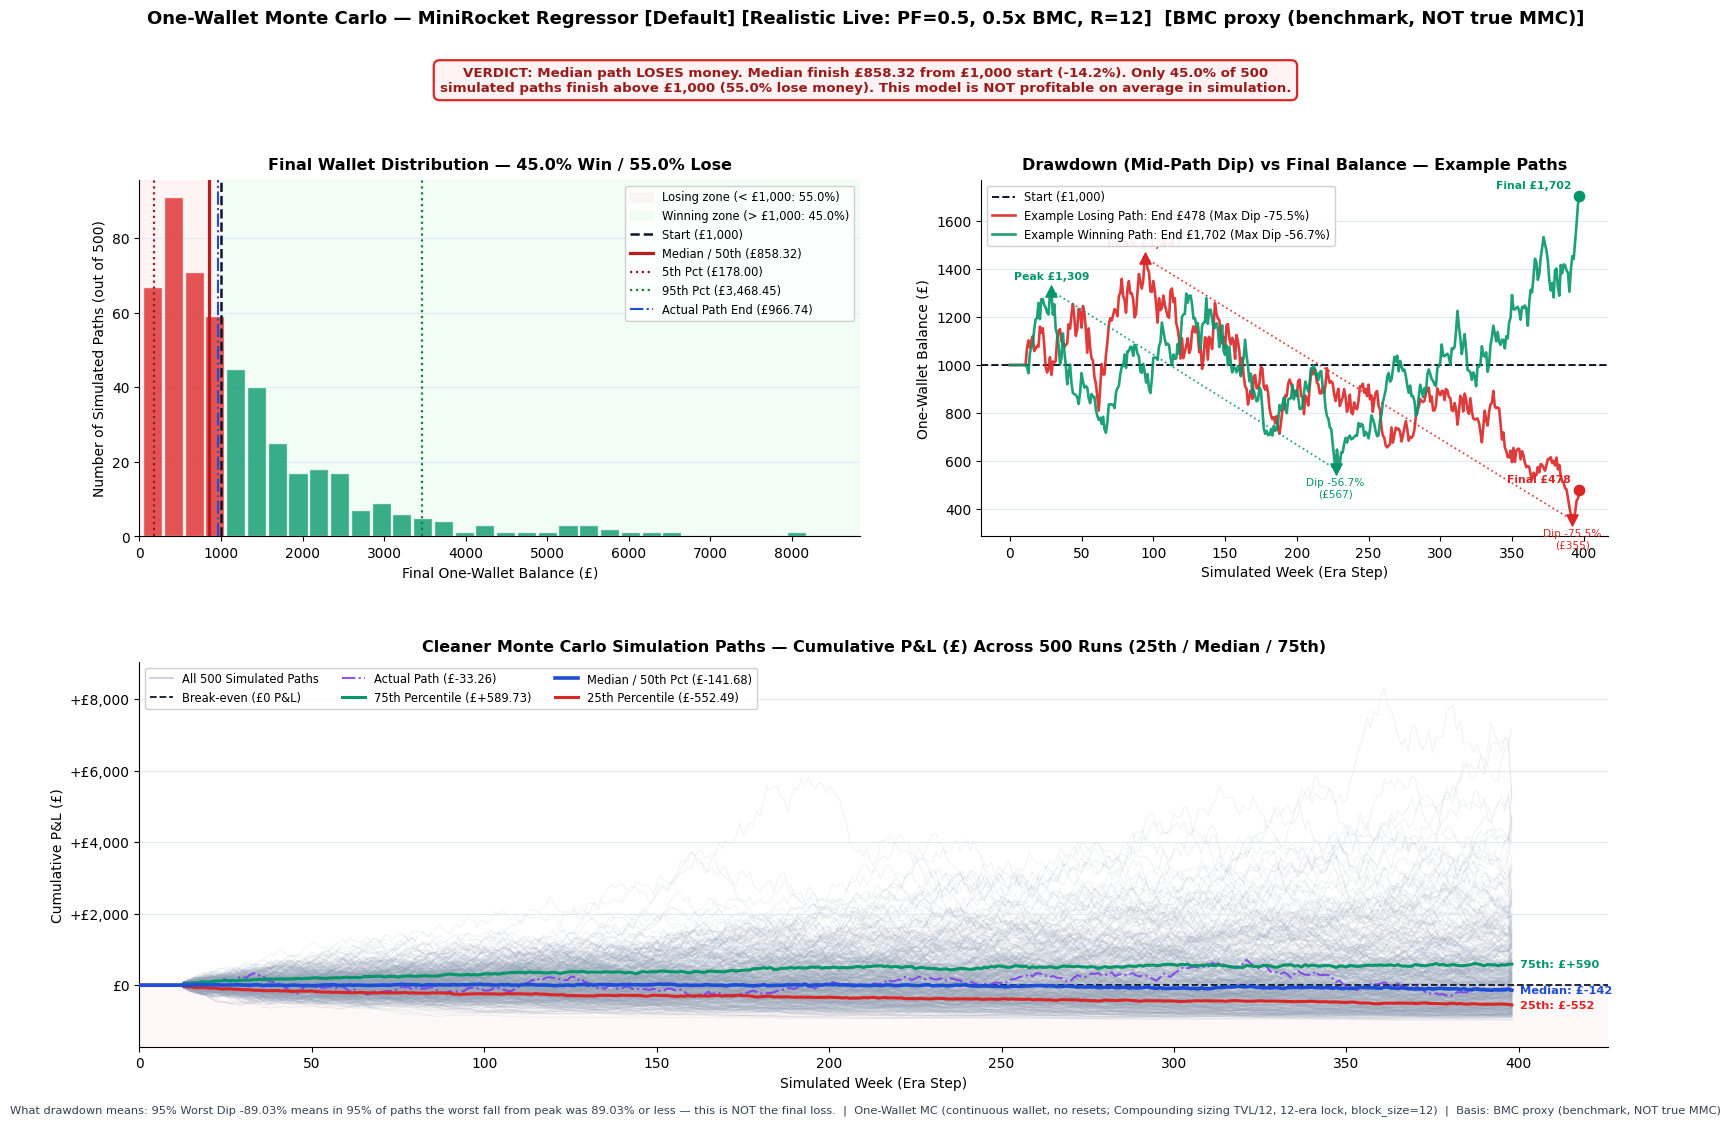

MiniRocket Regressor [Default] — VERDICT: Median path LOSES money. Median finish £858.32 from £1,000 start (-14.2%). Only 45.0% of 500 simulated paths finish above £1,000 (55.0% lose money). This model is NOT profitable on average in simulation.

MiniRocket Regressor [Default] [Realistic Live: PF=0.5, 0.5x BMC, R=12] [One-Wallet MC | BMC proxy (benchmark, NOT true MMC) | Compounding] | P(Profit): 45.0% (55.0% lose) | Median (50th): £858.32 (-14.2%) | 5th Pct: £178.00 | 95th Pct: £3,468.45 | 95% Worst Dip: -89.03% | P(Ruin): 0.0%
  -> What drawdown means: 95% Worst Dip -89.03% means in 95% of paths the worst fall from peak was 89.03% or less — this is NOT the final loss.
  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)=57.6% | Median=£1,074.87 | 95% Worst Dip=-48.11%


In [22]:
mc_risk_by_variant = {}
explainer_printed = False
staking_is_proxy = bool(v6_contrib_info['mmc_is_proxy'])
for variant_name in comparison_df['variant'].tolist():
    is_best_variant = (variant_name == best_variant_name)
    variant_slug = (
        variant_name.lower()
        .replace(' ', '_')
        .replace('[', '')
        .replace(']', '')
        .replace('-', '_')
    )
    mc_save_path = (
        results_dir / f'{timestamp}_{experiment_name}_{variant_slug}_monte_carlo_pnl.png'
        if save_results
        else None
    )
    title_label = f'[CV-LOCKED WINNER] {variant_name}' if is_best_variant else variant_name
    raw_contrib = variant_era_mmc_by_variant.get(variant_name)
    haircutted_contrib = (
        pd.Series(raw_contrib, dtype=np.float64) * (0.5 if staking_is_proxy else 1.0)
        if raw_contrib is not None
        else None
    )
    if haircutted_contrib is not None:
        haircutted_contrib.name = 'bmc_proxy' if staking_is_proxy else 'mmc'
    v_mc = plot_stake_pnl_monte_carlo(
        model_results[variant_name]['validation_era_corrs'],
        per_era_mmc=haircutted_contrib,
        mmc_is_proxy=staking_is_proxy,
        title=f'{title_label} [Realistic Live: PF=0.5, 0.5x BMC, R=12]',
        total_capital=1000.0,
        concurrent_rounds=12,
        settlement_rounds=12,
        payout_factor=0.5,
        payout_rule='auto',
        staking_mode='compound',
        n_sims=500,
        block_size=12,
        random_state=random_state,
        era_dates=val_era_dates,
        save_path=mc_save_path,
    )
    mc_risk_by_variant[variant_name] = v_mc
    c_mc = live_scenarios_by_variant[variant_name]['conservative_floor']['mc']
    print('=' * 100)
    print(f"{title_label} — {v_mc['mc_verdict_text']}")
    if not explainer_printed:
        print()
        print(v_mc['mc_explainer_text'])
        explainer_printed = True
    print()
    print(v_mc['mc_summary_line'])
    print(f"  -> {v_mc['mc_drawdown_explanation_line']}")
    print(
        f"  -> Conservative Floor MC (CORR only, PF=0.5, R=12): P(Profit)={c_mc['mc_prob_profit_pct']:.1f}% | "
        f"Median=£{c_mc['mc_median_final_stake']:,.2f} | 95% Worst Dip={c_mc['mc_p95_money_drawdown_pct']:.2f}%"
    )
    print('=' * 100)

## Optional Community Companion: `numereval` (Council of Elders)
Runs `councilofelders/numereval` alongside official `numerai-tools` metrics when installed locally (skips gracefully on Kaggle if unavailable). **Note:** `numereval` uses classic Spearman diagnostics and is not the official v6.0 Unity `NCORR` / `NMMC` / staking calculation.

In [23]:
numereval_summary_df = run_numereval_diagnostics(
    y_validation,
    model_results[best_variant_name]['validation_preds'],
    validation_eras,
    variant_name=best_variant_name,
    plot=False,
    verbose=True,
)
if numereval_summary_df is not None:
    display(numereval_summary_df)

[numereval companion — MiniRocket Regressor [Tuned]] Community Spearman diagnostics (informational alongside official numerai_tools v6.0 metrics; NOT official v6.0 NCORR/NMMC):


,metrics
mean,0.0043
std,0.1218
sharpe,0.0353
max_drawdown,-6.8555


## Optional Experiment Tracking (Weights & Biases)

In [24]:
if use_wandb:
    if wandb is None:
        print('Skipping W&B logging: wandb is not installed.')
    else:
        wandb_run = wandb.init(
            project=wandb_project,
            name=experiment_name,
            config={
                'data_version': data_version,
                'era_tag': era_tag,
                'model_tag': model_tag,
                'TARGET_COL': TARGET_COL,
                'feature_set': feature_set,
                'era_stride': era_stride,
                'search_mode': search_mode,
                'cv_strategy': cv_strategy,
                'n_splits': n_splits,
                'cv_split': cv_split,
                'downsample_mode': downsample_mode,
                'downsample_frac': downsample_frac,
                'val_downsample_mode': val_downsample_mode,
                'val_downsample_frac': val_downsample_frac,
                'target_horizon_eras': target_horizon_eras,
                'embargo_eras': embargo_eras,
                'eval_mode': eval_mode,
                'walk_forward_step_eras': walk_forward_step_eras,
                'walk_forward_window': walk_forward_window,
                'era_weighting': era_weighting,
                'recency_decay': recency_decay,
                'random_state': random_state,
                'n_iter': n_iter,
                'verbose': verbose,
                'n_jobs': n_jobs,
                'lgbm_n_jobs': lgbm_n_jobs,
                'error_bin_mode': error_bin_mode,
            },
        )
        log_payload = {
            'comparison_table': wandb.Table(dataframe=comparison_df),
            'search_summary_table': wandb.Table(dataframe=search_summary_df.drop(columns=['best_params'], errors='ignore')),
            'timing/prep_elapsed_s': float(prep_elapsed_s),
            'timing/train_elapsed_s': float(train_elapsed_s),
        }
        for m_name, m_cv_df in cv_results_by_model.items():
            m_slug = m_name.lower().replace(' ', '_')
            log_payload[f'cv_table/{m_slug}'] = wandb.Table(dataframe=m_cv_df.astype(str))
        for row in search_summary_rows:
            m_slug = row['model'].lower().replace(' ', '_')
            log_payload[f'best_cv_corr/{m_slug}'] = float(row['best_cv_corr'])
        wandb.log(log_payload)
        wandb.finish()
        print('Logged experiment tables and metrics to Weights & Biases.')
else:
    print('W&B tracking disabled (use_wandb=False).')

W&B tracking disabled (use_wandb=False).
